# **Data Cleaning, EDA, Data Visualization & Data Analysis of retail store sales**

# 🎯**Objective:**
The goal is to clean the dirty dataset, perform exploratory data analysis (EDA), data visualizations, and finding insights from the cleaned dataset to analyse the customer purchasing behaviour, and the sales of products in each category in the retail store through online and in-store shopping.

# 📦**Imports**

In [199]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import os

# 📁**Loading dataset**

In [200]:
os.makedirs("/kaggle/working/plots/",exist_ok=True)
retail_store_sales = pd.read_csv("/kaggle/input/datasets/ahmedmohamed2003/retail-store-sales-dirty-for-data-cleaning/retail_store_sales.csv")
retail_store_sales

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
...,...,...,...,...,...,...,...,...,...,...,...
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True


# 🔍**Initial Data Exploration (EDA)**

### **Shape and structure**

In [201]:
retail_store_sales.shape

(12575, 11)

In [202]:
retail_store_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              11362 non-null  object 
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(8)
memory usage: 1.1+ MB


### **Descriptive analysis**

In [203]:
retail_store_sales.describe(include="all")

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
count,12575,12575,12575,11362,11966.000000,11971.000000,11971.000000,12575,12575,12575,8376
unique,12575,25,8,200,NaN,NaN,NaN,3,2,1114,2
top,TXN_2407494,CUST_05,Electric household essentials,Item_2_BEV,NaN,NaN,NaN,Cash,Online,2022-05-30,True
freq,1,544,1591,126,NaN,NaN,NaN,4310,6354,26,4219
mean,NaN,NaN,NaN,NaN,23.365912,5.536380,129.652577,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,10.743519,2.857883,94.750697,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,5.000000,1.000000,5.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,14.000000,3.000000,51.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,23.000000,6.000000,108.500000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,33.500000,8.000000,192.000000,NaN,NaN,NaN,NaN


In [204]:
retail_store_sales.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


### **Count of missing values**

In [205]:
retail_store_sales.isna().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

### **Percentage of missing values**

In [206]:
retail_store_sales.isnull().mean()*100

Transaction ID       0.000000
Customer ID          0.000000
Category             0.000000
Item                 9.646123
Price Per Unit       4.842942
Quantity             4.803181
Total Spent          4.803181
Payment Method       0.000000
Location             0.000000
Transaction Date     0.000000
Discount Applied    33.391650
dtype: float64

### **Datatype checking**

In [207]:
retail_store_sales.dtypes

Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

### **Duplicate rows check**

In [208]:
retail_store_sales[retail_store_sales.duplicated]

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied


#### **Observations:**
- There are no duplicate rows in the dataset.

# 🧹**Data Cleaning**

## **Dropping irrelevant column**

In [209]:
retail_store_sales = retail_store_sales.drop(columns=["Transaction ID"],axis=1)
retail_store_sales.head()

,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


## **Standardizing column names**

In [210]:
retail_store_sales.columns = retail_store_sales.columns.str.strip().str.lower().str.replace(" ","_")
retail_store_sales

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
...,...,...,...,...,...,...,...,...,...,...
12570,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True


## **Filling missing data with values from catalogue**

In [211]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==33.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_20_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==33.5)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
7,CUST_21,Furniture,Item_20_FUR,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
393,CUST_21,Furniture,Item_20_FUR,33.5,2.0,67.0,Cash,Online,2022-09-13,False
411,CUST_05,Furniture,Item_20_FUR,33.5,1.0,33.5,Digital Wallet,In-store,2022-09-29,False
493,CUST_07,Furniture,Item_20_FUR,33.5,NaN,NaN,Digital Wallet,In-store,2023-02-24,NaN
673,CUST_03,Furniture,Item_20_FUR,33.5,1.0,33.5,Cash,Online,2024-11-18,NaN
...,...,...,...,...,...,...,...,...,...,...
11925,CUST_19,Furniture,Item_20_FUR,33.5,NaN,NaN,Credit Card,Online,2022-07-12,True
11953,CUST_08,Furniture,Item_20_FUR,33.5,4.0,134.0,Cash,Online,2024-11-05,False
12063,CUST_09,Furniture,Item_20_FUR,33.5,9.0,301.5,Credit Card,Online,2022-08-30,NaN
12130,CUST_13,Furniture,Item_20_FUR,33.5,2.0,67.0,Credit Card,Online,2022-04-05,False


In [212]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==35.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_21_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==35.0)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
19,CUST_01,Furniture,Item_21_FUR,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
86,CUST_17,Furniture,Item_21_FUR,35.0,3.0,105.0,Digital Wallet,Online,2023-04-01,NaN
138,CUST_25,Furniture,Item_21_FUR,35.0,NaN,NaN,Credit Card,Online,2022-12-18,False
648,CUST_24,Furniture,Item_21_FUR,35.0,2.0,70.0,Digital Wallet,In-store,2023-09-20,True
658,CUST_24,Furniture,Item_21_FUR,35.0,10.0,350.0,Digital Wallet,Online,2023-06-19,False
...,...,...,...,...,...,...,...,...,...,...
11827,CUST_20,Furniture,Item_21_FUR,35.0,1.0,35.0,Cash,Online,2024-11-02,NaN
11890,CUST_20,Furniture,Item_21_FUR,35.0,10.0,350.0,Cash,Online,2022-06-05,False
12220,CUST_02,Furniture,Item_21_FUR,35.0,5.0,175.0,Digital Wallet,Online,2023-07-21,NaN
12237,CUST_21,Furniture,Item_21_FUR,35.0,4.0,140.0,Cash,In-store,2022-01-05,False


In [213]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==39.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_24_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==39.5)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
25,CUST_05,Furniture,Item_24_FUR,39.5,NaN,NaN,Cash,Online,2022-09-08,False
87,CUST_18,Furniture,Item_24_FUR,39.5,9.0,355.5,Credit Card,In-store,2022-12-07,False
131,CUST_12,Furniture,Item_24_FUR,39.5,4.0,158.0,Digital Wallet,In-store,2022-04-14,True
204,CUST_24,Furniture,Item_24_FUR,39.5,5.0,197.5,Credit Card,In-store,2024-11-27,NaN
306,CUST_15,Furniture,Item_24_FUR,39.5,9.0,355.5,Digital Wallet,In-store,2024-12-25,False
...,...,...,...,...,...,...,...,...,...,...
12228,CUST_10,Furniture,Item_24_FUR,39.5,8.0,316.0,Credit Card,In-store,2022-06-20,False
12302,CUST_12,Furniture,Item_24_FUR,39.5,1.0,39.5,Digital Wallet,Online,2024-06-05,False
12363,CUST_07,Furniture,Item_24_FUR,39.5,1.0,39.5,Digital Wallet,In-store,2024-04-11,False
12410,CUST_03,Furniture,Item_24_FUR,39.5,NaN,NaN,Credit Card,In-store,2022-05-27,NaN


In [214]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==24.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_14_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==24.5)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
24,CUST_13,Furniture,Item_14_FUR,24.5,2.0,49.0,Cash,Online,2023-08-29,False
139,CUST_15,Furniture,Item_14_FUR,24.5,NaN,NaN,Cash,In-store,2024-09-30,True
256,CUST_16,Furniture,Item_14_FUR,24.5,1.0,24.5,Digital Wallet,In-store,2022-06-20,NaN
378,CUST_05,Furniture,Item_14_FUR,24.5,4.0,98.0,Cash,In-store,2023-06-12,NaN
445,CUST_05,Furniture,Item_14_FUR,24.5,4.0,98.0,Credit Card,In-store,2022-10-26,True
566,CUST_03,Furniture,Item_14_FUR,24.5,7.0,171.5,Cash,Online,2022-12-26,True
616,CUST_03,Furniture,Item_14_FUR,24.5,2.0,49.0,Digital Wallet,In-store,2022-04-29,NaN
961,CUST_19,Furniture,Item_14_FUR,24.5,2.0,49.0,Digital Wallet,In-store,2022-04-29,NaN
977,CUST_15,Furniture,Item_14_FUR,24.5,8.0,196.0,Cash,Online,2022-01-05,True
1190,CUST_11,Furniture,Item_14_FUR,24.5,1.0,24.5,Credit Card,Online,2022-03-07,False


In [215]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==12.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_6_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==12.5)&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["item"]=="Item_6_FUR")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
253,CUST_24,Furniture,Item_6_FUR,12.5,NaN,NaN,Digital Wallet,Online,2024-01-14,False
466,CUST_23,Furniture,Item_6_FUR,12.5,10.0,125.0,Credit Card,In-store,2022-04-22,True
516,CUST_24,Furniture,Item_6_FUR,12.5,3.0,37.5,Credit Card,Online,2022-05-07,NaN
628,CUST_17,Furniture,Item_6_FUR,12.5,9.0,112.5,Credit Card,In-store,2024-05-25,False
1033,CUST_25,Furniture,Item_6_FUR,12.5,NaN,NaN,Credit Card,In-store,2022-10-03,False
...,...,...,...,...,...,...,...,...,...,...
11835,CUST_15,Furniture,Item_6_FUR,12.5,1.0,12.5,Cash,Online,2022-05-04,False
12051,CUST_18,Furniture,Item_6_FUR,12.5,8.0,100.0,Credit Card,Online,2024-12-31,True
12348,CUST_19,Furniture,Item_6_FUR,12.5,7.0,87.5,Credit Card,In-store,2023-01-29,NaN
12434,CUST_11,Furniture,Item_6_FUR,12.5,4.0,50.0,Credit Card,In-store,2022-01-01,NaN


In [216]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==14.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_7_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==14.0)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
55,CUST_15,Furniture,Item_7_FUR,14.0,3.0,42.0,Digital Wallet,In-store,2023-04-02,NaN
702,CUST_24,Furniture,Item_7_FUR,14.0,7.0,98.0,Credit Card,Online,2022-10-24,True
783,CUST_12,Furniture,Item_7_FUR,14.0,7.0,98.0,Credit Card,Online,2022-05-29,True
824,CUST_08,Furniture,Item_7_FUR,14.0,8.0,112.0,Credit Card,Online,2023-03-19,False
974,CUST_02,Furniture,Item_7_FUR,14.0,1.0,14.0,Digital Wallet,Online,2024-10-13,False
1011,CUST_16,Furniture,Item_7_FUR,14.0,7.0,98.0,Credit Card,In-store,2024-05-18,True
1093,CUST_01,Furniture,Item_7_FUR,14.0,3.0,42.0,Credit Card,In-store,2024-05-16,True
1195,CUST_23,Furniture,Item_7_FUR,14.0,1.0,14.0,Digital Wallet,Online,2023-12-31,False
1206,CUST_04,Furniture,Item_7_FUR,14.0,4.0,56.0,Credit Card,Online,2023-01-28,True
1387,CUST_22,Furniture,Item_7_FUR,14.0,10.0,140.0,Credit Card,Online,2024-08-08,False


In [217]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==9.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_4_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==9.5)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
360,CUST_21,Furniture,Item_4_FUR,9.5,8.0,76.0,Cash,In-store,2023-01-08,True
514,CUST_04,Furniture,Item_4_FUR,9.5,4.0,38.0,Cash,Online,2024-01-25,True
594,CUST_08,Furniture,Item_4_FUR,9.5,NaN,NaN,Credit Card,Online,2024-08-25,False
745,CUST_19,Furniture,Item_4_FUR,9.5,2.0,19.0,Cash,Online,2022-04-19,NaN
1554,CUST_13,Furniture,Item_4_FUR,9.5,5.0,47.5,Cash,In-store,2022-08-26,True
1575,CUST_12,Furniture,Item_4_FUR,9.5,5.0,47.5,Cash,In-store,2023-01-01,True
2093,CUST_15,Furniture,Item_4_FUR,9.5,NaN,NaN,Cash,Online,2025-01-16,True
2186,CUST_16,Furniture,Item_4_FUR,9.5,3.0,28.5,Cash,Online,2024-03-18,False
2333,CUST_03,Furniture,Item_4_FUR,9.5,9.0,85.5,Credit Card,In-store,2024-09-29,False
2707,CUST_13,Furniture,Item_4_FUR,9.5,1.0,9.5,Credit Card,In-store,2023-02-05,NaN


In [218]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==20.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_11_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==20.0)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
82,CUST_09,Furniture,Item_11_FUR,20.0,8.0,160.0,Digital Wallet,In-store,2024-08-22,False
475,CUST_24,Furniture,Item_11_FUR,20.0,3.0,60.0,Digital Wallet,Online,2024-03-25,False
510,CUST_09,Furniture,Item_11_FUR,20.0,3.0,60.0,Credit Card,Online,2022-06-07,False
557,CUST_24,Furniture,Item_11_FUR,20.0,8.0,160.0,Digital Wallet,Online,2023-06-07,False
558,CUST_15,Furniture,Item_11_FUR,20.0,8.0,160.0,Cash,Online,2023-12-28,True
...,...,...,...,...,...,...,...,...,...,...
12292,CUST_05,Furniture,Item_11_FUR,20.0,3.0,60.0,Cash,In-store,2023-07-28,NaN
12352,CUST_17,Furniture,Item_11_FUR,20.0,4.0,80.0,Digital Wallet,In-store,2023-11-28,NaN
12388,CUST_01,Furniture,Item_11_FUR,20.0,6.0,120.0,Cash,In-store,2024-02-08,NaN
12515,CUST_22,Furniture,Item_11_FUR,20.0,2.0,40.0,Digital Wallet,Online,2024-08-05,False


In [219]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==41.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_25_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==41.0)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
27,CUST_14,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2024-03-24,True
107,CUST_01,Furniture,Item_25_FUR,41.0,7.0,287.0,Digital Wallet,In-store,2022-03-02,False
133,CUST_25,Furniture,Item_25_FUR,41.0,10.0,410.0,Credit Card,In-store,2023-08-10,NaN
164,CUST_22,Furniture,Item_25_FUR,41.0,1.0,41.0,Credit Card,In-store,2024-03-16,False
178,CUST_22,Furniture,Item_25_FUR,41.0,2.0,82.0,Credit Card,Online,2022-01-13,NaN
...,...,...,...,...,...,...,...,...,...,...
11939,CUST_08,Furniture,Item_25_FUR,41.0,8.0,328.0,Digital Wallet,In-store,2024-08-16,False
12189,CUST_18,Furniture,Item_25_FUR,41.0,10.0,410.0,Digital Wallet,In-store,2024-01-27,False
12270,CUST_16,Furniture,Item_25_FUR,41.0,1.0,41.0,Credit Card,In-store,2022-09-02,True
12438,CUST_23,Furniture,Item_25_FUR,41.0,4.0,164.0,Digital Wallet,Online,2024-11-22,False


In [220]:
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==6.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_2_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==26.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_15_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==5.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_1_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==27.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_16_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==15.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_8_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==29.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_17_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==21.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_12_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==8.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_3_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==18.5)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_10_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==38.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_23_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna()==True)&(retail_store_sales["price_per_unit"]==11.0)&(retail_store_sales["category"]=="Furniture"),"item"]="Item_5_FUR"
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
354,CUST_24,Furniture,NaN,NaN,7.0,182.0,Digital Wallet,In-store,2022-02-07,NaN
419,CUST_19,Furniture,NaN,NaN,1.0,27.5,Credit Card,Online,2022-03-21,False
542,CUST_12,Furniture,NaN,NaN,2.0,76.0,Credit Card,Online,2022-06-12,True
699,CUST_16,Furniture,NaN,NaN,3.0,105.0,Cash,Online,2024-06-23,False
700,CUST_24,Furniture,NaN,NaN,2.0,10.0,Digital Wallet,In-store,2023-07-14,True
...,...,...,...,...,...,...,...,...,...,...
12123,CUST_13,Furniture,NaN,NaN,9.0,342.0,Digital Wallet,In-store,2022-03-17,NaN
12143,CUST_15,Furniture,NaN,NaN,6.0,39.0,Digital Wallet,Online,2023-06-29,NaN
12163,CUST_02,Furniture,NaN,NaN,5.0,122.5,Cash,In-store,2024-07-24,True
12386,CUST_11,Furniture,NaN,NaN,7.0,266.0,Cash,In-store,2022-08-10,True


In [221]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture"),"price_per_unit"] = retail_store_sales["total_spent"]/retail_store_sales["quantity"]
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
354,CUST_24,Furniture,NaN,26.0,7.0,182.0,Digital Wallet,In-store,2022-02-07,NaN
419,CUST_19,Furniture,NaN,27.5,1.0,27.5,Credit Card,Online,2022-03-21,False
542,CUST_12,Furniture,NaN,38.0,2.0,76.0,Credit Card,Online,2022-06-12,True
699,CUST_16,Furniture,NaN,35.0,3.0,105.0,Cash,Online,2024-06-23,False
700,CUST_24,Furniture,NaN,5.0,2.0,10.0,Digital Wallet,In-store,2023-07-14,True
...,...,...,...,...,...,...,...,...,...,...
12123,CUST_13,Furniture,NaN,38.0,9.0,342.0,Digital Wallet,In-store,2022-03-17,NaN
12143,CUST_15,Furniture,NaN,6.5,6.0,39.0,Digital Wallet,Online,2023-06-29,NaN
12163,CUST_02,Furniture,NaN,24.5,5.0,122.5,Cash,In-store,2024-07-24,True
12386,CUST_11,Furniture,NaN,38.0,7.0,266.0,Cash,In-store,2022-08-10,True


In [222]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==6.5),"item"] = "Item_2_FUR"
retail_store_sales[(retail_store_sales["price_per_unit"]==6.5)&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
149,CUST_25,Furniture,Item_2_FUR,6.5,5.0,32.5,Digital Wallet,In-store,2023-07-19,NaN
300,CUST_12,Furniture,Item_2_FUR,6.5,6.0,39.0,Digital Wallet,Online,2024-06-18,True
429,CUST_14,Furniture,Item_2_FUR,6.5,6.0,39.0,Digital Wallet,Online,2024-11-06,NaN
437,CUST_22,Furniture,Item_2_FUR,6.5,5.0,32.5,Cash,In-store,2022-06-25,False
486,CUST_21,Furniture,Item_2_FUR,6.5,9.0,58.5,Digital Wallet,Online,2023-07-12,False
...,...,...,...,...,...,...,...,...,...,...
12143,CUST_15,Furniture,Item_2_FUR,6.5,6.0,39.0,Digital Wallet,Online,2023-06-29,NaN
12215,CUST_04,Furniture,Item_2_FUR,6.5,8.0,52.0,Digital Wallet,Online,2022-11-05,True
12357,CUST_12,Furniture,Item_2_FUR,6.5,7.0,45.5,Digital Wallet,In-store,2023-10-29,NaN
12435,CUST_01,Furniture,Item_2_FUR,6.5,5.0,32.5,Credit Card,Online,2023-09-06,True


In [223]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==38.0),"item"] = "Item_23_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==11.0),"item"] = "Item_5_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==39.5),"item"] = "Item_24_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==26.0),"item"] = "Item_15_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==33.5),"item"] = "Item_20_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==35.0),"item"] = "Item_21_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==32.0),"item"] = "Item_19_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==20.0),"item"] = "Item_11_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==9.5),"item"] = "Item_4_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==27.5),"item"] = "Item_16_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==15.5),"item"] = "Item_8_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==5.0),"item"] = "Item_1_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==14.0),"item"] = "Item_7_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==17.0),"item"] = "Item_9_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==41.0),"item"] = "Item_25_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==18.5),"item"] = "Item_10_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==24.5),"item"] = "Item_14_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==12.5),"item"] = "Item_6_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==36.5),"item"] = "Item_22_FUR"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")&(retail_store_sales["price_per_unit"]==29.0),"item"] = "Item_17_FUR"
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [224]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==38.0),"item"] = "Item_23_EHE"
retail_store_sales[(retail_store_sales["price_per_unit"]==38.0)&(retail_store_sales["category"]=="Electric household essentials")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
192,CUST_16,Electric household essentials,Item_23_EHE,38.0,1.0,38.0,Cash,In-store,2022-03-21,True
234,CUST_14,Electric household essentials,Item_23_EHE,38.0,NaN,NaN,Cash,Online,2023-08-16,False
412,CUST_24,Electric household essentials,Item_23_EHE,38.0,6.0,228.0,Credit Card,Online,2024-01-20,True
485,CUST_05,Electric household essentials,Item_23_EHE,38.0,10.0,380.0,Digital Wallet,In-store,2022-08-18,False
635,CUST_23,Electric household essentials,Item_23_EHE,38.0,9.0,342.0,Cash,Online,2024-04-28,True
...,...,...,...,...,...,...,...,...,...,...
12001,CUST_21,Electric household essentials,Item_23_EHE,38.0,6.0,228.0,Cash,In-store,2025-01-06,False
12359,CUST_04,Electric household essentials,Item_23_EHE,38.0,6.0,228.0,Credit Card,In-store,2023-12-22,True
12407,CUST_10,Electric household essentials,Item_23_EHE,38.0,8.0,304.0,Credit Card,Online,2024-05-25,True
12433,CUST_05,Electric household essentials,Item_23_EHE,38.0,7.0,266.0,Credit Card,In-store,2022-10-02,False


In [225]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==33.5),"item"] = "Item_20_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==29.0),"item"] = "Item_17_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==23.0),"item"] = "Item_13_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==26.0),"item"] = "Item_15_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==41.0),"item"] = "Item_25_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==32.0),"item"] = "Item_19_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==6.5),"item"] = "Item_2_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==21.5),"item"] = "Item_12_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==15.5),"item"] = "Item_8_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==35.0),"item"] = "Item_21_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==17.0),"item"] = "Item_9_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==24.5),"item"] = "Item_14_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==12.5),"item"] = "Item_6_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==11.0),"item"] = "Item_5_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==36.5),"item"] = "Item_22_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==9.5),"item"] = "Item_4_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==18.5),"item"] = "Item_10_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==27.5),"item"] = "Item_16_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==14.0),"item"] = "Item_7_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==5.0),"item"] = "Item_1_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==39.5),"item"] = "Item_24_EHE"
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
247,CUST_24,Electric household essentials,NaN,NaN,7.0,150.5,Cash,Online,2023-03-30,NaN
389,CUST_03,Electric household essentials,NaN,NaN,8.0,220.0,Credit Card,Online,2022-08-12,NaN
526,CUST_20,Electric household essentials,NaN,NaN,7.0,108.5,Digital Wallet,Online,2022-06-17,False
1191,CUST_10,Electric household essentials,NaN,NaN,1.0,33.5,Digital Wallet,In-store,2022-04-01,False
1408,CUST_02,Electric household essentials,NaN,NaN,3.0,100.5,Cash,Online,2024-04-20,True
...,...,...,...,...,...,...,...,...,...,...
12124,CUST_07,Electric household essentials,NaN,NaN,4.0,50.0,Credit Card,Online,2023-01-23,NaN
12299,CUST_12,Electric household essentials,NaN,NaN,3.0,69.0,Credit Card,Online,2022-10-14,True
12339,CUST_17,Electric household essentials,NaN,NaN,3.0,123.0,Digital Wallet,Online,2024-05-24,True
12365,CUST_07,Electric household essentials,NaN,NaN,3.0,78.0,Cash,Online,2022-05-15,True


In [226]:
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")]["quantity"].unique()

array([ 7.,  8.,  1.,  3.,  5., 10.,  4.,  6.,  2.,  9.])

In [227]:
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")]["total_spent"].unique()

array([150.5, 220. , 108.5,  33.5, 100.5, 182.5,  29. , 380. , 146. ,
        11. , 280. , 192. ,  34. , 148. ,  46. ,  88. , 109.5,  77.5,
       124. , 320. , 152. , 246. , 205. ,  92. ,  61. ,  67. ,  87.5,
        22. , 268. ,  75. ,  78. , 207. , 140. , 247.5, 301.5,  62. ,
        55. ,  56. , 255.5, 230. ,  86. , 342. , 410. ,  18.5, 128. ,
       123. ,  64. , 234.5,  20. ,  46.5,  47.5, 165. , 183. , 369. ,
        36.5,  76. , 112. , 304. ,  82. ,  39. , 112.5, 180. , 120. ,
        50. ,  69. ])

In [228]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials"),"price_per_unit"] = retail_store_sales["total_spent"]/retail_store_sales["quantity"]
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
247,CUST_24,Electric household essentials,NaN,21.5,7.0,150.5,Cash,Online,2023-03-30,NaN
389,CUST_03,Electric household essentials,NaN,27.5,8.0,220.0,Credit Card,Online,2022-08-12,NaN
526,CUST_20,Electric household essentials,NaN,15.5,7.0,108.5,Digital Wallet,Online,2022-06-17,False
1191,CUST_10,Electric household essentials,NaN,33.5,1.0,33.5,Digital Wallet,In-store,2022-04-01,False
1408,CUST_02,Electric household essentials,NaN,33.5,3.0,100.5,Cash,Online,2024-04-20,True
...,...,...,...,...,...,...,...,...,...,...
12124,CUST_07,Electric household essentials,NaN,12.5,4.0,50.0,Credit Card,Online,2023-01-23,NaN
12299,CUST_12,Electric household essentials,NaN,23.0,3.0,69.0,Credit Card,Online,2022-10-14,True
12339,CUST_17,Electric household essentials,NaN,41.0,3.0,123.0,Digital Wallet,Online,2024-05-24,True
12365,CUST_07,Electric household essentials,NaN,26.0,3.0,78.0,Cash,Online,2022-05-15,True


In [229]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==21.5),"item"]="Item_12_EHE"
retail_store_sales[(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==21.5)]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
202,CUST_12,Electric household essentials,Item_12_EHE,21.5,2.0,43.0,Digital Wallet,In-store,2023-09-09,True
247,CUST_24,Electric household essentials,Item_12_EHE,21.5,7.0,150.5,Cash,Online,2023-03-30,NaN
346,CUST_17,Electric household essentials,Item_12_EHE,21.5,2.0,43.0,Cash,Online,2023-09-18,NaN
372,CUST_18,Electric household essentials,Item_12_EHE,21.5,2.0,43.0,Cash,Online,2022-09-10,False
430,CUST_02,Electric household essentials,Item_12_EHE,21.5,7.0,150.5,Cash,In-store,2024-03-14,True
...,...,...,...,...,...,...,...,...,...,...
11773,CUST_18,Electric household essentials,Item_12_EHE,21.5,6.0,129.0,Digital Wallet,Online,2024-11-12,False
11822,CUST_04,Electric household essentials,Item_12_EHE,21.5,6.0,129.0,Credit Card,Online,2022-11-26,False
12167,CUST_20,Electric household essentials,Item_12_EHE,21.5,9.0,193.5,Credit Card,In-store,2023-12-31,False
12457,CUST_17,Electric household essentials,Item_12_EHE,21.5,4.0,86.0,Credit Card,Online,2023-02-26,NaN


In [230]:
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==41.0),"item"]="Item_25_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==33.5),"item"]="Item_20_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==38.0),"item"]="Item_23_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==36.5),"item"]="Item_22_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==23.0),"item"]="Item_13_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==15.5),"item"]="Item_8_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==12.5),"item"]="Item_6_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==27.5),"item"]="Item_16_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==32.0),"item"]="Item_19_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==20.0),"item"]="Item_11_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==11.0),"item"]="Item_5_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==18.5),"item"]="Item_10_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==26.0),"item"]="Item_15_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==14.0),"item"]="Item_7_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==35.0),"item"]="Item_21_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==30.5),"item"]="Item_18_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==17.0),"item"]="Item_9_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==29.0),"item"]="Item_17_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==9.5),"item"]="Item_4_EHE"
retail_store_sales.loc[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")&(retail_store_sales["price_per_unit"]==6.5),"item"]="Item_2_EHE"
retail_store_sales[(retail_store_sales["item"].isna())&(retail_store_sales["category"]=="Electric household essentials")]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [231]:
retail_store_sales.loc[(retail_store_sales["price_per_unit"].isna())&(retail_store_sales["quantity"].isna()==False)&(retail_store_sales["total_spent"].isna()==False),"price_per_unit"] = retail_store_sales["total_spent"]/retail_store_sales["quantity"]
retail_store_sales[retail_store_sales["price_per_unit"].isna()]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [232]:
retail_store_sales[retail_store_sales["total_spent"].isna()==False]["total_spent"].sum()

np.float64(1552071.0)

In [233]:
retail_store_sales.loc[(retail_store_sales["total_spent"].isna()==False)&(retail_store_sales["quantity"].isna()==False),"total_spent"] = retail_store_sales["price_per_unit"]*retail_store_sales["quantity"]
retail_store_sales[(retail_store_sales["total_spent"].isna()==False)]["total_spent"].sum()

np.float64(1552071.0)

## **Filling missing data of a column with unknown**

In [234]:
retail_store_sales = retail_store_sales.fillna({"item":"Unknown"})
retail_store_sales[retail_store_sales["item"].isna()]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


## **Filling missing data of two numerical columns with 1**

In [235]:
retail_store_sales = retail_store_sales.fillna({"quantity":1,"total_spent":1})
retail_store_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       12575 non-null  object 
 1   category          12575 non-null  object 
 2   item              12575 non-null  object 
 3   price_per_unit    12575 non-null  float64
 4   quantity          12575 non-null  float64
 5   total_spent       12575 non-null  float64
 6   payment_method    12575 non-null  object 
 7   location          12575 non-null  object 
 8   transaction_date  12575 non-null  object 
 9   discount_applied  8376 non-null   object 
dtypes: float64(3), object(7)
memory usage: 982.6+ KB


In [236]:
retail_store_sales["total_spent"] = retail_store_sales["price_per_unit"]*retail_store_sales["quantity"]
retail_store_sales[retail_store_sales["quantity"]==1]

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
7,CUST_21,Furniture,Item_20_FUR,33.5,1.0,33.5,Digital Wallet,In-store,2024-04-02,True
8,CUST_23,Furniture,Item_16_FUR,27.5,1.0,27.5,Credit Card,In-store,2023-04-26,False
15,CUST_14,Beverages,Unknown,24.5,1.0,24.5,Credit Card,In-store,2022-05-11,NaN
18,CUST_17,Electric household essentials,Item_13_EHE,23.0,1.0,23.0,Digital Wallet,In-store,2022-02-07,False
19,CUST_01,Furniture,Item_21_FUR,35.0,1.0,35.0,Digital Wallet,Online,2025-01-13,False
...,...,...,...,...,...,...,...,...,...,...
12527,CUST_23,Food,Unknown,5.0,1.0,5.0,Digital Wallet,In-store,2022-08-13,False
12552,CUST_05,Milk Products,Unknown,8.0,1.0,8.0,Cash,In-store,2022-07-21,False
12556,CUST_04,Beverages,Unknown,41.0,1.0,41.0,Credit Card,Online,2024-11-28,True
12562,CUST_07,Butchers,Unknown,33.5,1.0,33.5,Cash,Online,2023-04-15,NaN


## **Dropping column**

In [237]:
retail_store_sales = retail_store_sales.drop(columns=["discount_applied"],axis=1)
retail_store_sales

,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02
...,...,...,...,...,...,...,...,...,...
12570,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03
12571,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12
12572,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24
12573,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30


#### **Observations:**
- The column 'discount_applied' is removed as it has more than 30% of missing data which can be guessed to fill.

## **Renaming column names**

In [238]:
retail_store_sales = retail_store_sales.rename(columns={"item":"item_code"})
retail_store_sales.head()

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02


## **Creating new column**

In [239]:
retail_store_sales["item_name"] = "Unnamed"
retail_store_sales.head()

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,Unnamed
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,Unnamed
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,Unnamed
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unnamed
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,Unnamed


In [240]:
item_code_name_map = {"Item_1_EHE":"Blender","Item_2_EHE":"Microwave","Item_3_EHE":"Toaster","Item_4_EHE":"Vacuum Cleaner","Item_5_EHE":"Air Purifier","Item_6_EHE":"Electric Kettle","Item_7_EHE":"Rice Cooker","Item_8_EHE":"Iron","Item_9_EHE":"Ceiling Fan","Item_10_EHE":"Table Fan","Item_11_EHE":"Hair Dryer","Item_12_EHE":"Heater","Item_13_EHE":"Humidifier","Item_14_EHE":"Dehumidifier","Item_15_EHE":"Coffee Maker","Item_16_EHE":"Portable AC","Item_17_EHE":"Electric Stove","Item_18_EHE":"Pressure Cooker","Item_19_EHE":"Induction Cooktop","Item_20_EHE":"Water Dispenser","Item_21_EHE":"Hand Blender","Item_22_EHE":"Mixer Grinder","Item_23_EHE":"Sandwich Maker","Item_24_EHE":"Air Fryer","Item_25_EHE":"Juicer","Item_1_FUR":"Office Chair","Item_2_FUR":"Sofa","Item_3_FUR":"Coffee Table","Item_4_FUR":"Dining Table","Item_5_FUR":"Bookshelf","Item_6_FUR":"Bed Frame","Item_7_FUR":"Wardrobe","Item_8_FUR":"Study Table","Item_9_FUR":"Recliner","Item_10_FUR":"Side Table","Item_11_FUR":"TV Stand","Item_12_FUR":"Dressing Table","Item_13_FUR":"Chest of Drawers","Item_14_FUR":"Ottoman","Item_15_FUR":"Rocking Chair","Item_16_FUR":"Shoe Rack","Item_17_FUR":"Nightstand","Item_18_FUR":"Patio Chair","Item_19_FUR":"Folding Table","Item_20_FUR":"Bean Bag","Item_21_FUR":"Wooden Bench","Item_22_FUR":"Corner Shelf","Item_23_FUR":"Magazine Rack","Item_24_FUR":"Bar Stool","Item_25_FUR":"Accent Chair"}
retail_store_sales["item_name"] = retail_store_sales["item_code"].apply(lambda code_word:item_code_name_map.get(code_word) if code_word in item_code_name_map else "Unnamed")
retail_store_sales[retail_store_sales["category"]=="Electric household essentials"]

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name
18,CUST_17,Electric household essentials,Item_13_EHE,23.0,1.0,23.0,Digital Wallet,In-store,2022-02-07,Humidifier
22,CUST_10,Electric household essentials,Item_4_EHE,9.5,7.0,66.5,Cash,In-store,2022-08-15,Vacuum Cleaner
33,CUST_12,Electric household essentials,Item_21_EHE,35.0,9.0,315.0,Credit Card,In-store,2024-03-07,Hand Blender
41,CUST_16,Electric household essentials,Item_10_EHE,18.5,5.0,92.5,Cash,Online,2022-08-01,Table Fan
81,CUST_10,Electric household essentials,Item_21_EHE,35.0,2.0,70.0,Digital Wallet,In-store,2023-05-09,Hand Blender
...,...,...,...,...,...,...,...,...,...,...
12519,CUST_11,Electric household essentials,Item_21_EHE,35.0,1.0,35.0,Digital Wallet,In-store,2022-04-21,Hand Blender
12529,CUST_03,Electric household essentials,Item_20_EHE,33.5,8.0,268.0,Credit Card,Online,2023-05-06,Water Dispenser
12549,CUST_14,Electric household essentials,Item_5_EHE,11.0,8.0,88.0,Digital Wallet,In-store,2023-06-11,Air Purifier
12560,CUST_20,Electric household essentials,Item_12_EHE,21.5,8.0,172.0,Digital Wallet,Online,2024-10-14,Heater


In [241]:
retail_store_sales[(retail_store_sales["category"]=="Furniture")]

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name
7,CUST_21,Furniture,Item_20_FUR,33.5,1.0,33.5,Digital Wallet,In-store,2024-04-02,Bean Bag
8,CUST_23,Furniture,Item_16_FUR,27.5,1.0,27.5,Credit Card,In-store,2023-04-26,Shoe Rack
19,CUST_01,Furniture,Item_21_FUR,35.0,1.0,35.0,Digital Wallet,Online,2025-01-13,Wooden Bench
24,CUST_13,Furniture,Item_14_FUR,24.5,2.0,49.0,Cash,Online,2023-08-29,Ottoman
25,CUST_05,Furniture,Item_24_FUR,39.5,1.0,39.5,Cash,Online,2022-09-08,Bar Stool
...,...,...,...,...,...,...,...,...,...,...
12541,CUST_06,Furniture,Item_12_FUR,21.5,6.0,129.0,Credit Card,Online,2024-05-24,Dressing Table
12543,CUST_19,Furniture,Item_6_FUR,12.5,9.0,112.5,Digital Wallet,Online,2024-06-29,Bed Frame
12547,CUST_02,Furniture,Item_15_FUR,26.0,5.0,130.0,Credit Card,In-store,2022-02-05,Rocking Chair
12548,CUST_06,Furniture,Item_11_FUR,20.0,9.0,180.0,Credit Card,In-store,2022-01-21,TV Stand


## **Checking unique data**

In [242]:
retail_store_sales["item_name"].unique()

array(['Unnamed', 'Bean Bag', 'Shoe Rack', 'Humidifier', 'Wooden Bench',
       'Vacuum Cleaner', 'Ottoman', 'Bar Stool', 'Accent Chair',
       'Hand Blender', 'Side Table', 'Table Fan', 'Magazine Rack',
       'Wardrobe', 'Corner Shelf', 'TV Stand', 'Electric Kettle',
       'Bookshelf', 'Iron', 'Office Chair', 'Sofa', 'Study Table',
       'Rice Cooker', 'Induction Cooktop', 'Nightstand',
       'Water Dispenser', 'Portable AC', 'Sandwich Maker', 'Blender',
       'Heater', 'Mixer Grinder', 'Electric Stove', 'Juicer', 'Bed Frame',
       'Rocking Chair', 'Air Purifier', 'Hair Dryer', 'Dining Table',
       'Coffee Maker', 'Recliner', 'Dressing Table', 'Air Fryer',
       'Microwave', 'Ceiling Fan', 'Pressure Cooker', 'Coffee Table',
       'Folding Table', 'Dehumidifier', 'Patio Chair', 'Chest of Drawers',
       'Toaster'], dtype=object)

## **Changing Datatype**

In [243]:
retail_store_sales["transaction_date"] = pd.to_datetime(retail_store_sales["transaction_date"],format="%Y-%m-%d")
retail_store_sales.head()

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,Unnamed
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,Unnamed
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,Unnamed
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unnamed
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,Unnamed


## **Creating multiple new columns by extracting data from existing column**

In [244]:
retail_store_sales["day_of_transaction"] = retail_store_sales["transaction_date"].dt.day
retail_store_sales["month_of_transaction"] = retail_store_sales["transaction_date"].dt.strftime("%B")
retail_store_sales["year_of_transaction"] = retail_store_sales["transaction_date"].dt.year
retail_store_sales

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name,day_of_transaction,month_of_transaction,year_of_transaction
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,Unnamed,8,April,2024
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,Unnamed,23,July,2023
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,Unnamed,5,October,2022
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unnamed,7,May,2022
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,Unnamed,2,October,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12570,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,Unnamed,3,September,2023
12571,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,Unnamed,12,August,2022
12572,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,Unnamed,24,August,2024
12573,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,Wardrobe,30,December,2023


In [245]:
retail_store_sales["day_name_of_purchase"] = retail_store_sales["transaction_date"].dt.day_name()
retail_store_sales.head()

,customer_id,category,item_code,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,item_name,day_of_transaction,month_of_transaction,year_of_transaction,day_name_of_purchase
0,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,Unnamed,8,April,2024,Monday
1,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,Unnamed,23,July,2023,Sunday
2,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,Unnamed,5,October,2022,Wednesday
3,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unnamed,7,May,2022,Saturday
4,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,Unnamed,2,October,2022,Sunday


## **Changing position of columns**

In [246]:
popped_item_name = retail_store_sales.pop("item_name")
retail_store_sales.insert(3,"item_name",popped_item_name)
retail_store_sales.head()

,customer_id,category,item_code,item_name,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,day_of_transaction,month_of_transaction,year_of_transaction,day_name_of_purchase
0,CUST_09,Patisserie,Item_10_PAT,Unnamed,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,8,April,2024,Monday
1,CUST_22,Milk Products,Item_17_MILK,Unnamed,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,23,July,2023,Sunday
2,CUST_02,Butchers,Item_12_BUT,Unnamed,21.5,2.0,43.0,Credit Card,Online,2022-10-05,5,October,2022,Wednesday
3,CUST_06,Beverages,Item_16_BEV,Unnamed,27.5,9.0,247.5,Credit Card,Online,2022-05-07,7,May,2022,Saturday
4,CUST_05,Food,Item_6_FOOD,Unnamed,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,2,October,2022,Sunday


## **Data validation after cleaning**

In [247]:
retail_store_sales.isna().sum()

customer_id             0
category                0
item_code               0
item_name               0
price_per_unit          0
quantity                0
total_spent             0
payment_method          0
location                0
transaction_date        0
day_of_transaction      0
month_of_transaction    0
year_of_transaction     0
day_name_of_purchase    0
dtype: int64

In [248]:
retail_store_sales.shape

(12575, 14)

### ✨**Cleaned Dataset**

In [249]:
retail_store_sales

,customer_id,category,item_code,item_name,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,day_of_transaction,month_of_transaction,year_of_transaction,day_name_of_purchase
0,CUST_09,Patisserie,Item_10_PAT,Unnamed,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,8,April,2024,Monday
1,CUST_22,Milk Products,Item_17_MILK,Unnamed,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,23,July,2023,Sunday
2,CUST_02,Butchers,Item_12_BUT,Unnamed,21.5,2.0,43.0,Credit Card,Online,2022-10-05,5,October,2022,Wednesday
3,CUST_06,Beverages,Item_16_BEV,Unnamed,27.5,9.0,247.5,Credit Card,Online,2022-05-07,7,May,2022,Saturday
4,CUST_05,Food,Item_6_FOOD,Unnamed,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,2,October,2022,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12570,CUST_18,Patisserie,Item_23_PAT,Unnamed,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,3,September,2023,Sunday
12571,CUST_03,Beverages,Item_2_BEV,Unnamed,6.5,9.0,58.5,Cash,Online,2022-08-12,12,August,2022,Friday
12572,CUST_11,Butchers,Item_7_BUT,Unnamed,14.0,10.0,140.0,Cash,Online,2024-08-24,24,August,2024,Saturday
12573,CUST_04,Furniture,Item_7_FUR,Wardrobe,14.0,6.0,84.0,Cash,Online,2023-12-30,30,December,2023,Saturday


In [250]:
retail_store_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   customer_id           12575 non-null  object        
 1   category              12575 non-null  object        
 2   item_code             12575 non-null  object        
 3   item_name             12575 non-null  object        
 4   price_per_unit        12575 non-null  float64       
 5   quantity              12575 non-null  float64       
 6   total_spent           12575 non-null  float64       
 7   payment_method        12575 non-null  object        
 8   location              12575 non-null  object        
 9   transaction_date      12575 non-null  datetime64[ns]
 10  day_of_transaction    12575 non-null  int32         
 11  month_of_transaction  12575 non-null  object        
 12  year_of_transaction   12575 non-null  int32         
 13  day_name_of_purc

# 📊**Data Visualization**

## 🏪**Univariate Analysis**

### **Distribution of the total amount spent by customers**

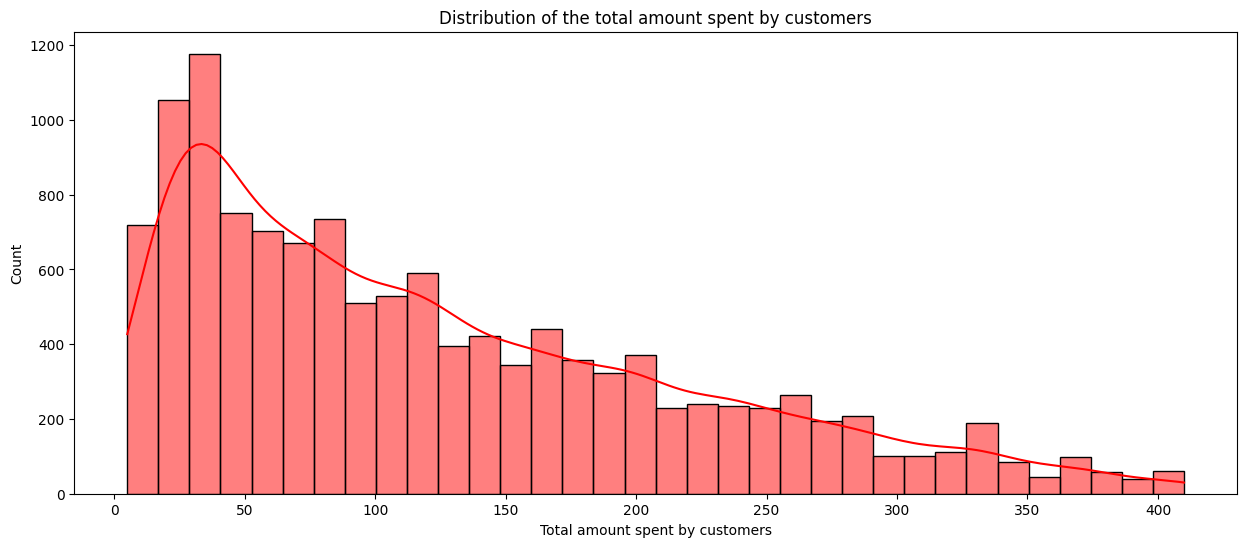

In [251]:
plt.figure(figsize=(15,6))
seaborn.histplot(retail_store_sales["total_spent"],color="red",kde=True)
plt.xlabel("Total amount spent by customers")
plt.title("Distribution of the total amount spent by customers")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_by_customers.png");

#### 💡**Insights:**
- Most of the customers have spent a total amount spent of around 25.
- The total amount spent by customers ranges between 5 and 420, where most of the customers have spent more on the lower amount, and few have paid for higher total amounts.

###**Total count of categories purchased by customer**

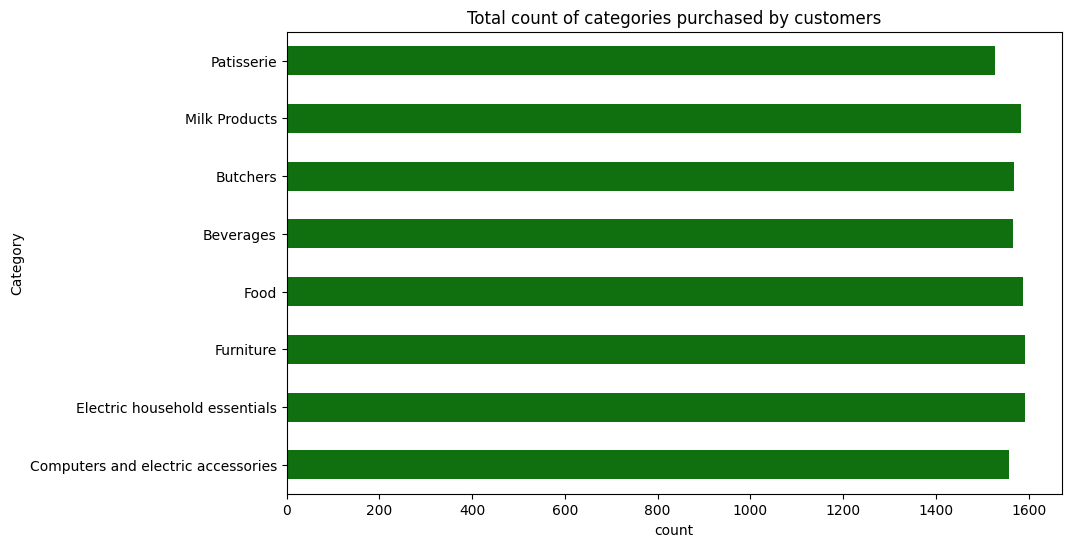

In [252]:
plt.figure(figsize=(10,6))
seaborn.countplot(data=retail_store_sales,y="category",color="green",width=0.5)
plt.title("Total count of categories purchased by customers")
plt.ylabel("Category")
plt.savefig("/kaggle/working/plots/total_count_of_categories_purchased_by_customers.png");

#### 💡**Insights:**
- Milk products, food, furniture, and electric household essentials are the categories which had the highest number of sales which is around 1600.

###**Distribution of price per unit**

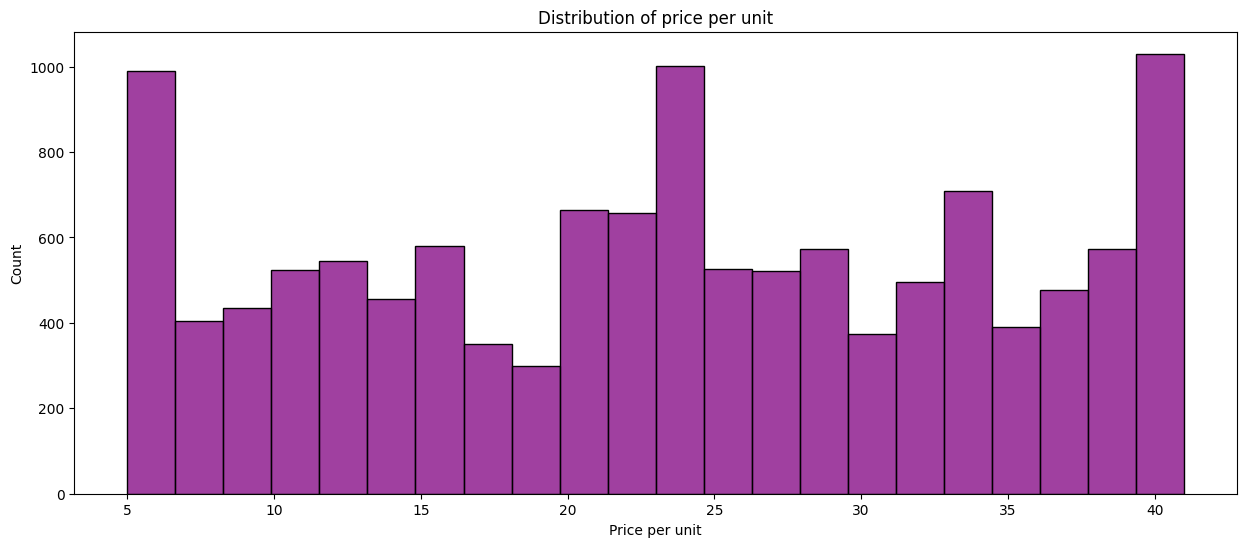

In [253]:
plt.figure(figsize=(15,6))
seaborn.histplot(data=retail_store_sales,x="price_per_unit",color="purple")
plt.xlabel("Price per unit")
plt.title("Distribution of price per unit")
plt.savefig("/kaggle/working/plots/distribution_of_price_per_unit.png");

#### 💡**Insights:**
- Most of the items in the retail store are priced as 5, 24, and 40.
- Less than 350 items have a price per unit of around 18.

###**Distribution of the quantity of products purchased by customers**

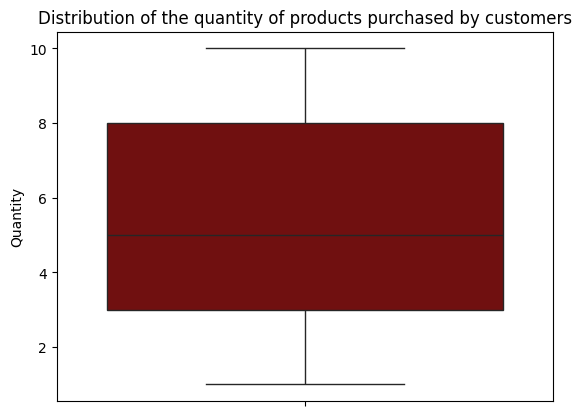

In [254]:
seaborn.boxplot(data=retail_store_sales,y="quantity",color="maroon")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of products purchased by customers")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_products_purchased_by_customers.png");

#### 💡**Insights:**
- Most of the customers have purchased 3 to 8 quantities of items.
- The quantity of items purchased by the customers are ranging between 1 to 10.

###**Total number of payments made by different payment methods**

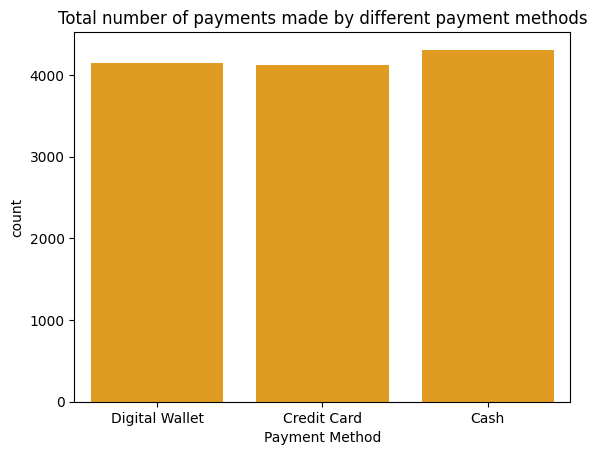

In [255]:
seaborn.countplot(data=retail_store_sales,x="payment_method",color="orange")
plt.xlabel("Payment Method")
plt.title("Total number of payments made by different payment methods")
plt.savefig("/kaggle/working/plots/total_number_of_payments_made_by_different_payment_methods.png");

#### 💡**Insights:**
- Most of the customers have made the payment through cash in the retail store.

###**Total number of purchases made by customers by location of purchase**

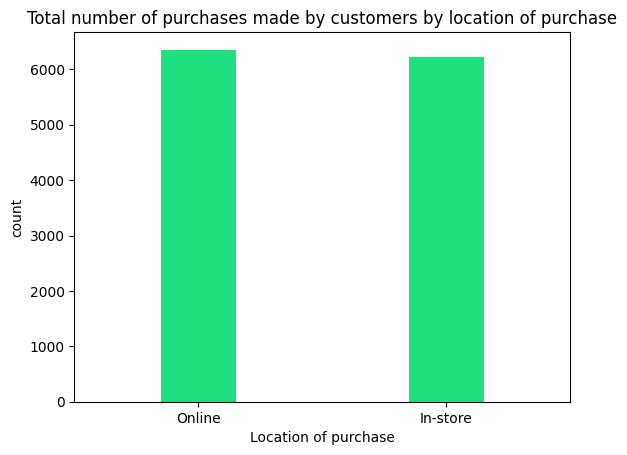

In [256]:
seaborn.countplot(data=retail_store_sales,x="location",width=0.3,color="springgreen")
plt.xlabel("Location of purchase")
plt.title("Total number of purchases made by customers by location of purchase")
plt.savefig("/kaggle/working/plots/total_number_of_purchases_made_by_customers_by_location_of_purchase.png");

#### 💡**Insights:**
- Most of the customers have purchased items from the retail store by online shopping.
- Around 6300 purchases are made through online shopping, and around 6000 purchases are in-store purchases.

###**Distribution of the total amount spent for computers and electric accessories**

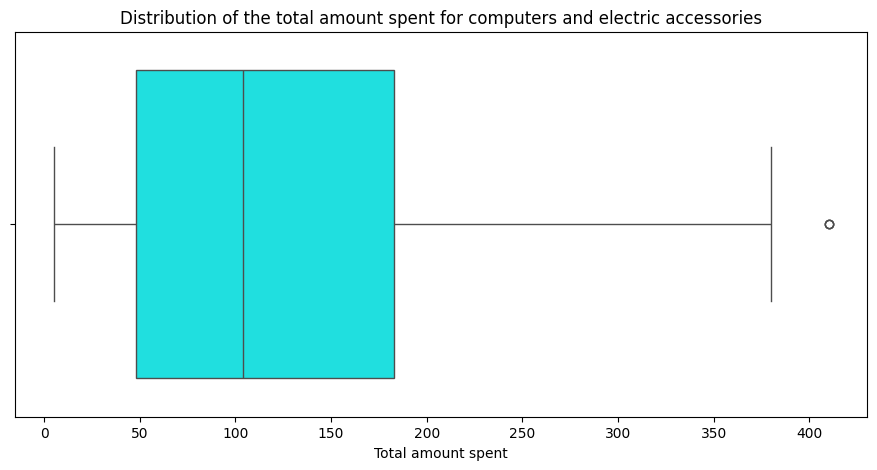

In [257]:
plt.figure(figsize=(11,5))
seaborn.boxplot(data=retail_store_sales[retail_store_sales["category"]=="Computers and electric accessories"],x="total_spent",color="cyan")
plt.xlabel("Total amount spent")
plt.title("Distribution of the total amount spent for computers and electric accessories")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_for_computers_and_electric_accessories.png");

#### 💡**Insights:**
- The total amount spent for items in the computers and electronic accessories is mostly between 50 to 180.
- Few of the purchases as total amount spent in the computers and electronic accessories category are above 400.

###**Distribution of the total amount spent by customers for furniture**

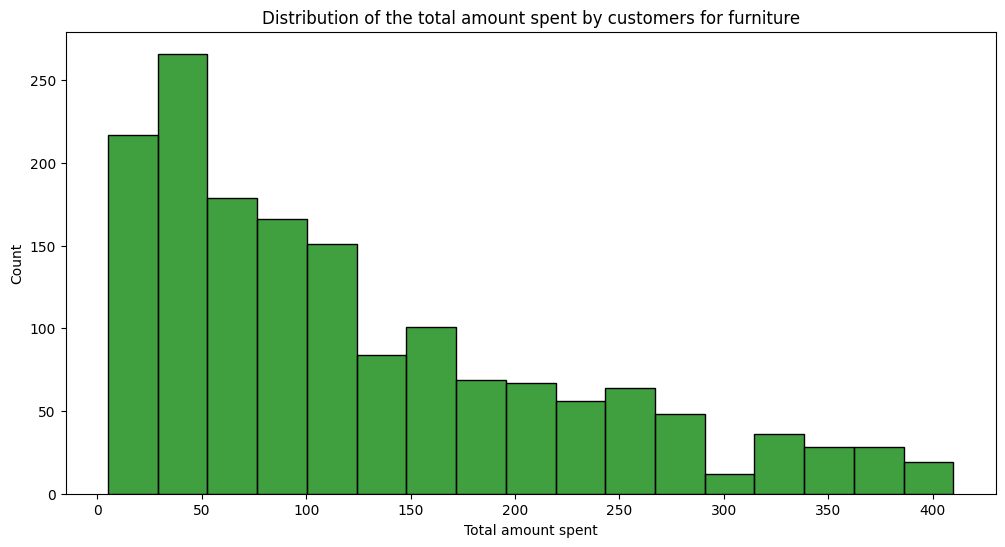

In [258]:
plt.figure(figsize=(12,6))
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Furniture"],x="total_spent",color="green")
plt.xlabel("Total amount spent")
plt.title("Distribution of the total amount spent by customers for furniture")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_by_customers_for_furniture.png");

#### 💡**Insights:**
- More than 250 purchases are made in the furniture section for a total amount  of between 40 to 50.
- Few purchases are made in the furniture section for a total amount of around 300.
- Most of the total amount spent is in smaller amounts, and a few transactions are for higher total amounts.

###**Distribution of total amount spent for electric household essentials**

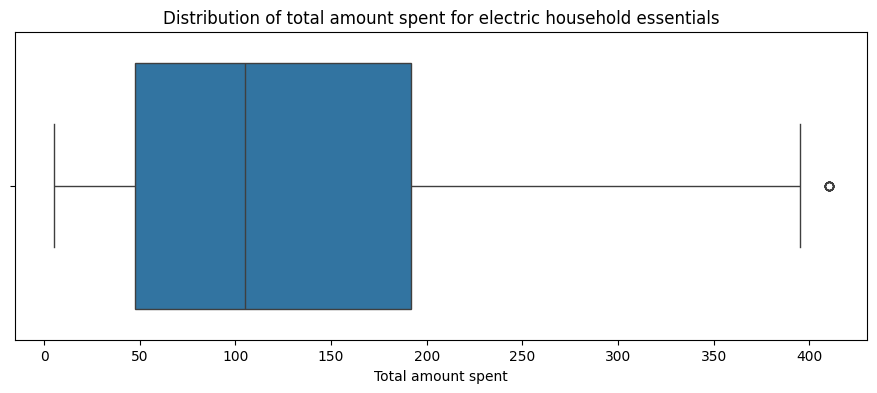

In [259]:
plt.figure(figsize=(11,4))
seaborn.boxplot(data=retail_store_sales[retail_store_sales["category"]=="Electric household essentials"],x="total_spent")
plt.xlabel("Total amount spent")
plt.title("Distribution of total amount spent for electric household essentials")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_for_electric_household_essentials.png");

#### 💡**Insights:**
- Most of the total amount spent on electric household essentials are between 50 to 190.
- Few of the total amount spent on electric household essentials is around 420.

###**Proportion of total sales by year**

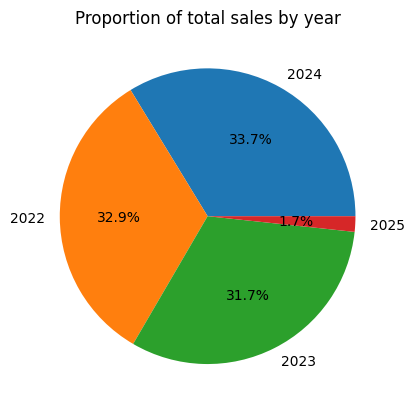

In [260]:
plt.pie(retail_store_sales["year_of_transaction"].value_counts().values,labels=retail_store_sales["year_of_transaction"].value_counts().index,autopct="%1.1f%%")
plt.title("Proportion of total sales by year")
plt.savefig("/kaggle/working/plots/proportion_of_total_sales_by_year.png");

#### 💡**Insights:**
- The year 2025 had less purchases in the retail store of 1.7%.
- Most of the sales happened in the year 2024 with a percentage of 33.7.

###**Total number of purchases by month**

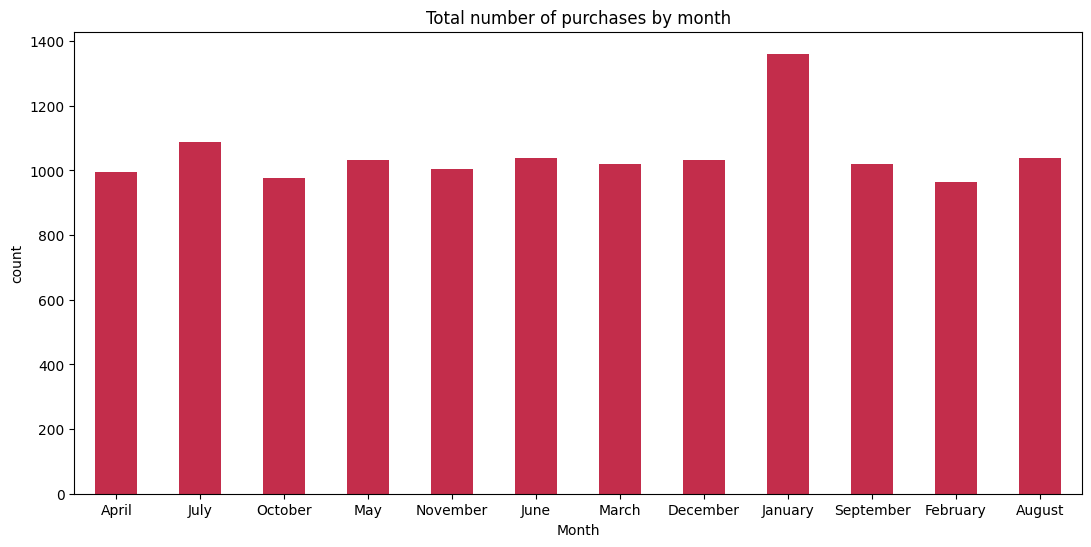

In [261]:
plt.figure(figsize=(13,6))
seaborn.countplot(data=retail_store_sales,x="month_of_transaction",width=0.5,color="crimson")
plt.xlabel("Month")
plt.title("Total number of purchases by month")
plt.savefig("/kaggle/working/plots/total_number_of_purchases_by_month.png");

#### 💡**Insights:**
- January had the highest number of purchases made by customers followed by July.
- February and October had the lowest number of purchases.

###**Distribution of price per unit of items in the butchers category**

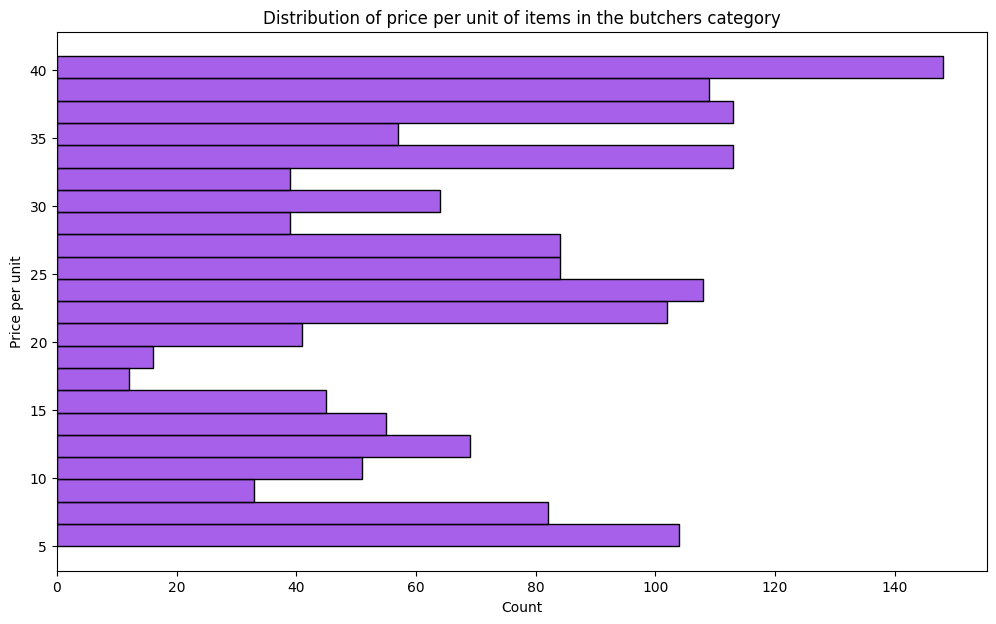

In [262]:
plt.figure(figsize=(12,7))
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Butchers"],y="price_per_unit",color="blueviolet",binwidth=1.6)
plt.ylabel("Price per unit")
plt.title("Distribution of price per unit of items in the butchers category")
plt.savefig("/kaggle/working/plots/distribution_of_price_per_unit_of_items_in_the_butchers_category.png");

#### 💡**Insights:**
- The costliest price per unit of items in the butchers category is around 40.
- Most of the items purchased from the butchers category has the price per unit of 40, followed by 34 and 36.
- Fewer items in the butchers category has the price per unit of around 17.5.

###**Comparison of the distribution of the total amount spent**

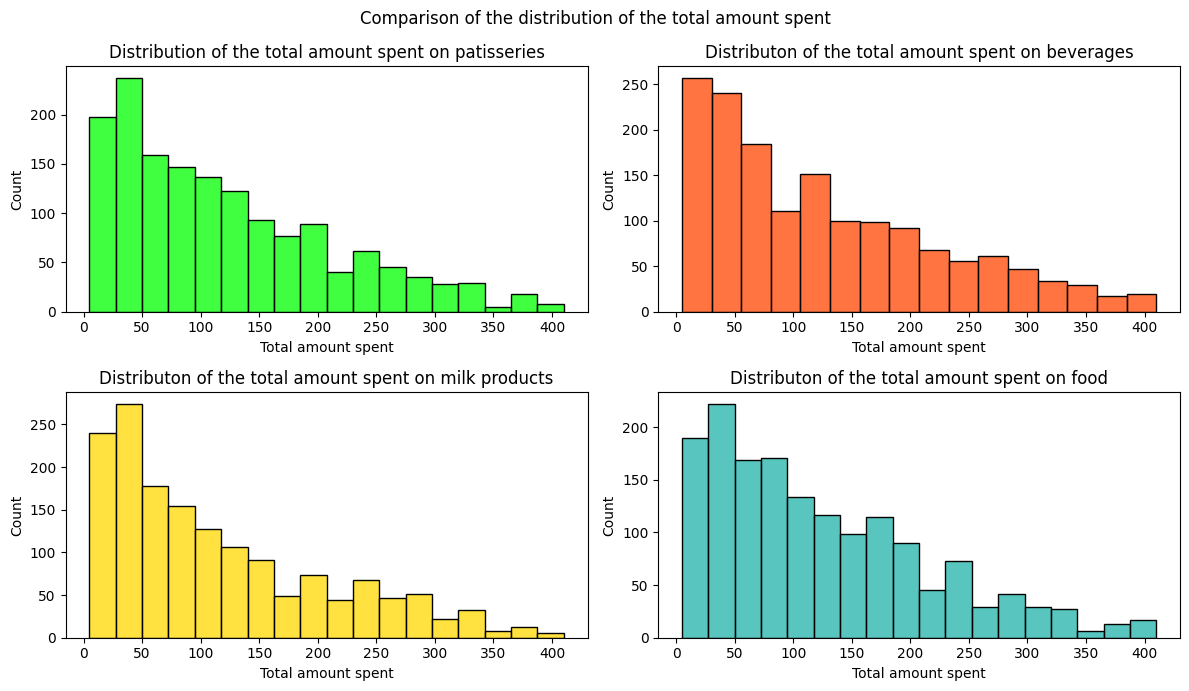

In [263]:
f, ax = plt.subplots(2,2,figsize=(12,7))
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Patisserie"],x="total_spent",ax=ax[0,0],color="lime")
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Beverages"],x="total_spent",ax=ax[0,1],color="orangered")
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Milk Products"],x="total_spent",ax=ax[1,0],color="gold")
seaborn.histplot(data=retail_store_sales[retail_store_sales["category"]=="Food"],x="total_spent",ax=ax[1,1],color="lightseagreen")
ax[0,0].set_xlabel("Total amount spent")
ax[0,0].set_title("Distribution of the total amount spent on patisseries")
ax[0,1].set_xlabel("Total amount spent")
ax[0,1].set_title("Distributon of the total amount spent on beverages")
ax[1,0].set_xlabel("Total amount spent")
ax[1,0].set_title("Distributon of the total amount spent on milk products")
ax[1,1].set_xlabel("Total amount spent")
ax[1,1].set_title("Distributon of the total amount spent on food")
f.suptitle("Comparison of the distribution of the total amount spent")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_the_distribution_of_the_total_amount_spent.png");

#### 💡**Insights:**
- Most of the total amount spent by customers on purchases in the food, milk products, patisseries, and beverages category is between 5 and 50.
- Very few customers have spent a total amount of 350 on items in patisseries, milk products, and food.

## 🏪**Bivariate Analysis**

###**Total amount spent by price per unit**

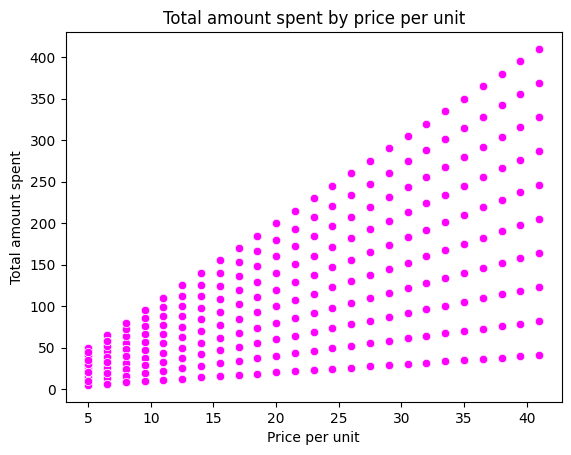

In [264]:
seaborn.scatterplot(data=retail_store_sales,x="price_per_unit",y="total_spent",color="magenta")
plt.xlabel("Price per unit")
plt.ylabel("Total amount spent")
plt.title("Total amount spent by price per unit")
plt.savefig("/kaggle/working/plots/total_amount_spent_by_price_per_unit.png");

#### 💡**Insights:**
- The total amount spent by customers is increasing with the price per unit of the items in all categories in the retail store.

###**Top 5 most purchased customers in the retail store**

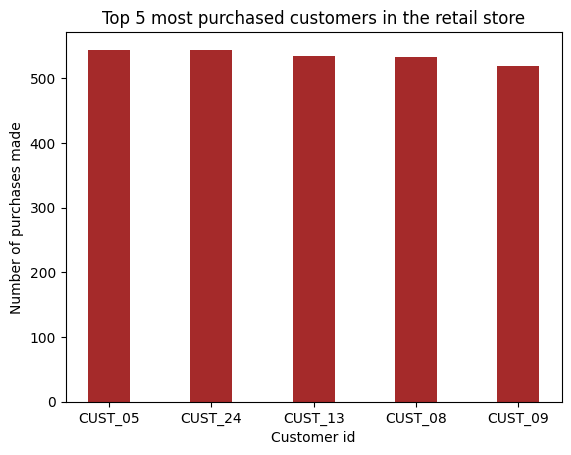

In [265]:
plt.bar(retail_store_sales["customer_id"].value_counts().head().index,retail_store_sales["customer_id"].value_counts().head().values,width=0.41,color="brown")
plt.xlabel("Customer id")
plt.ylabel("Number of purchases made")
plt.title("Top 5 most purchased customers in the retail store")
plt.savefig("/kaggle/working/plots/top_5_most_purchaed_customers_in_the_retail_store.png");

#### 💡**Insights:**
- The highest number of purchases in the retail store is by the customer with customer id CUST_05.
- CUST_05 has made more than 550 purchases in the retail store between 2022 to 2025.

###**Distribution of total amount spent by category of items**

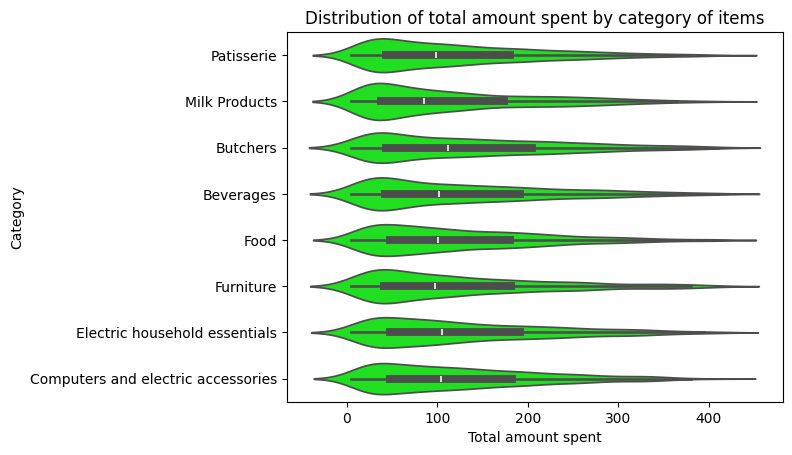

In [266]:
seaborn.violinplot(data=retail_store_sales,x="total_spent",y="category",color="lime")
plt.xlabel("Total amount spent")
plt.ylabel("Category")
plt.title("Distribution of total amount spent by category of items")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_by_category_of_items.png");

#### 💡**Insights:**
- Most of the total amount spent by customers are between 30 to 180 in all the categories.

###**Top 5 most purchased categories by customer with customer id CUST_05**

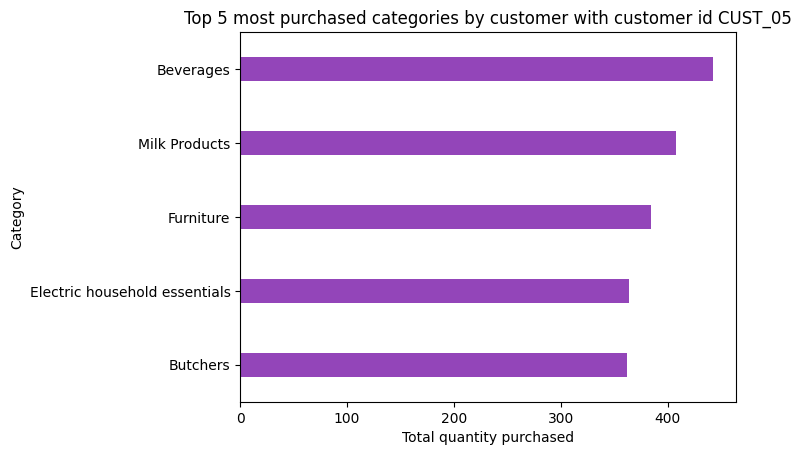

In [267]:
top_5_categories_purchased_by_cust_05 = retail_store_sales[retail_store_sales["customer_id"]=="CUST_05"].groupby("category")["quantity"].sum().sort_values(ascending=False).head(5)
seaborn.barplot(y=top_5_categories_purchased_by_cust_05.index,x=top_5_categories_purchased_by_cust_05.values,width=0.33,color="darkorchid")
plt.xlabel("Total quantity purchased")
plt.ylabel("Category")
plt.title("Top 5 most purchased categories by customer with customer id CUST_05")
plt.savefig("/kaggle/working/plots/top_5_most_purchased_categories_by_customer_with_customer_id_CUST_05.png");

#### 💡**Insights:**
- The items in the beverages and milk products are the top 2 most purchased categories by the customer with customer id of CUST_05.
- CUST_05 had purchased more than 400 items from the beverages and milk products category.
- The top categories purchased by the customer with customer id CUST_05 had a quantity of more than 350.

###**Top 10 furniture items purchased based on total amount spent by customers**

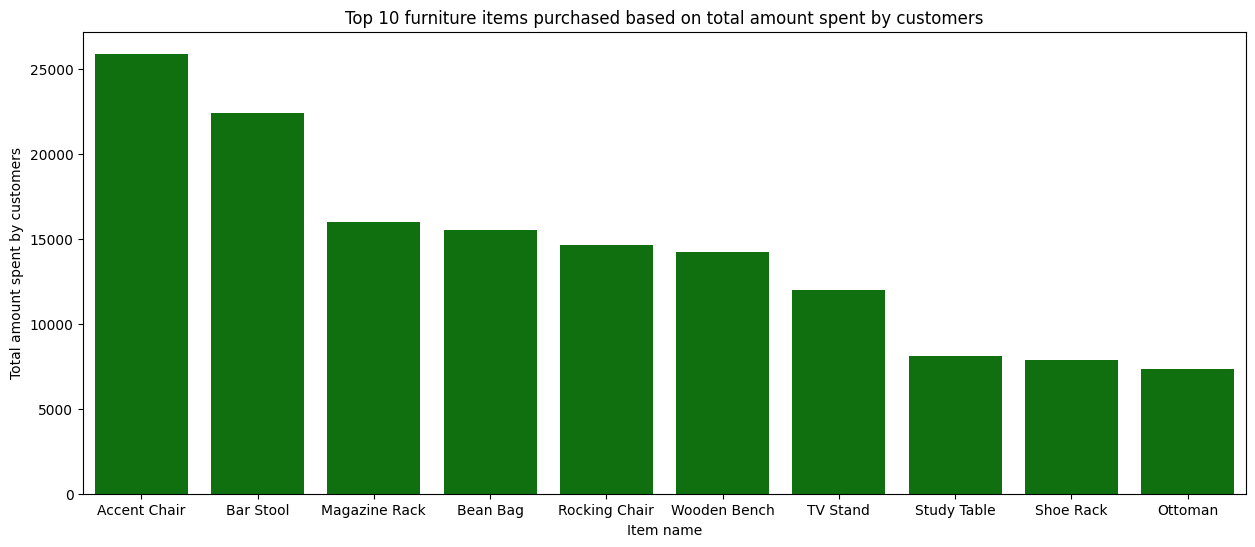

In [268]:
plt.figure(figsize=(15,6))
furniture_grouped_item_name = retail_store_sales[(retail_store_sales["category"]=="Furniture")].groupby("item_name")["total_spent"].sum().sort_values(ascending=False).head(10)
seaborn.barplot(x=furniture_grouped_item_name.index,y=furniture_grouped_item_name.values,color="green")
plt.xlabel("Item name")
plt.ylabel("Total amount spent by customers")
plt.title("Top 10 furniture items purchased based on total amount spent by customers")
plt.savefig("/kaggle/working/plots/top_10_furniture_items_purchased_based_on_total_amount_spent_by_customers.png");

#### 💡**Insights:**
- The accent chair tops the list among the top 10 furniture items purchased based on the total amount spent by customers.
- There is a vast price difference in the total amount spent by customers for purchasing a bar stool and magazine rack, which is around 6000.
- Beanbags are ranking in the fourth place among the top 10 furniture items bought by customers.

###**Top 10 electric household essential items purchased based on total amount spent by customers**

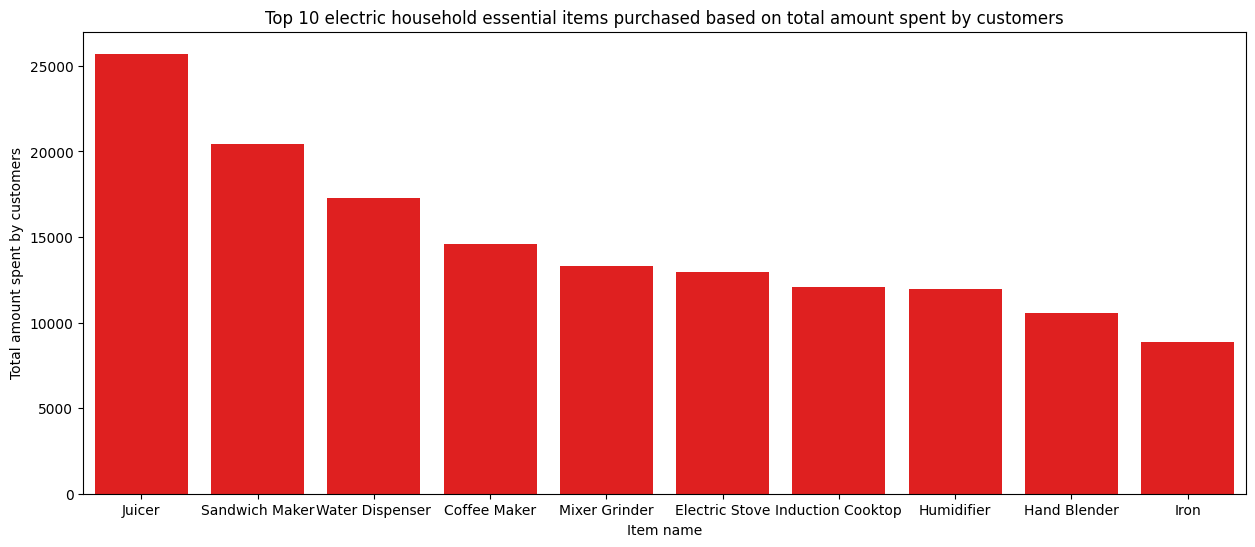

In [269]:
plt.figure(figsize=(15,6))
ehe_grouped_item_name = retail_store_sales[(retail_store_sales["category"]=="Electric household essentials")].groupby("item_name")["total_spent"].sum().sort_values(ascending=False).head(10)
seaborn.barplot(x=ehe_grouped_item_name.index,y=ehe_grouped_item_name.values,color="red")
plt.xlabel("Item name")
plt.ylabel("Total amount spent by customers")
plt.title("Top 10 electric household essential items purchased based on total amount spent by customers")
plt.savefig("/kaggle/working/plots/top_10_electric_household_essentials_items_purchased_based_on_total_amount_spent_by_customers.png");

#### 💡**Insights:**
- Juicer ranks in the first place among the top 10 electric household essentials based on the total amount spent.
- The total amount spent for the juicer is around 26000.
- The total amount spent by customers for purchasing a sandwich maker is around 20000.
- The total amount spent by customers for purchasing iron is around 11000, which is about half the total amount spent for sandwich makers.

###**Distribution of the total amount spent on furniture by item name**

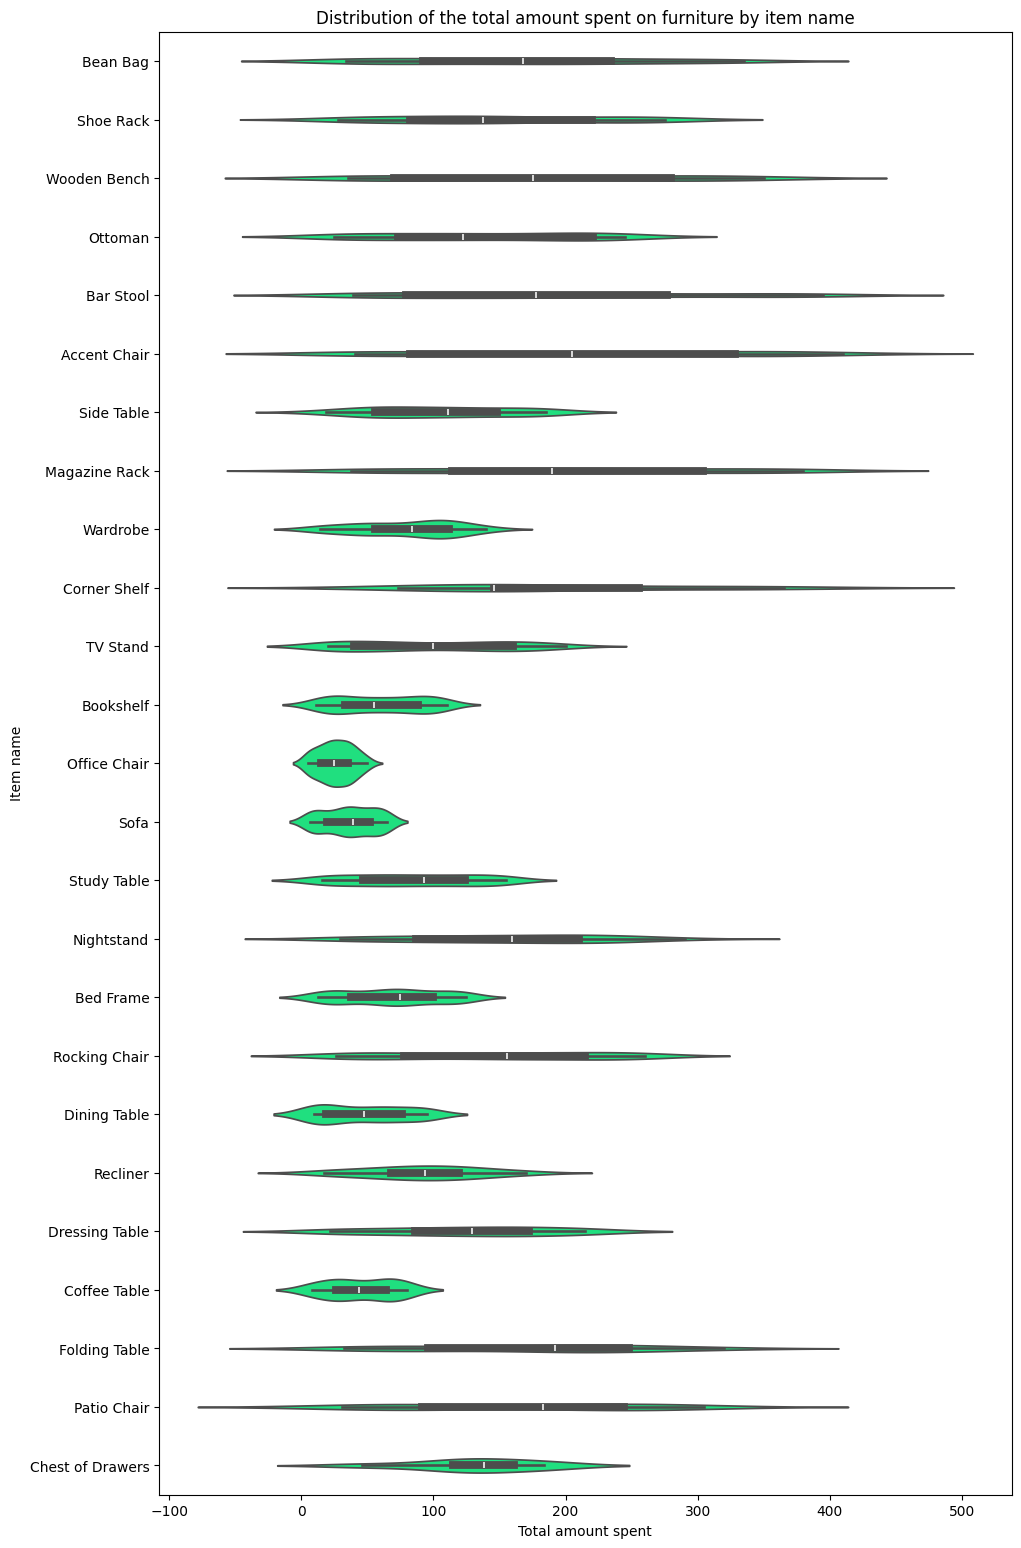

In [270]:
plt.figure(figsize=(11,19))
seaborn.violinplot(data=retail_store_sales[retail_store_sales["category"]=="Furniture"],x="total_spent",y="item_name",color="springgreen")
plt.xlabel("Total amount spent")
plt.ylabel("Item name")
plt.title("Distribution of the total amount spent on furniture by item name")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_on_furniture_by_item_name.png");

#### 💡**Insights:**
- Most of the total amount spent for coffee table is between 20 to 80.
- The sales of bean bag, and accent chair are high because most of the total amount spent for office chair and sofa is less than bean bag, and accent chair.

###**Distribution of the quantity of air fryers purchased by year**

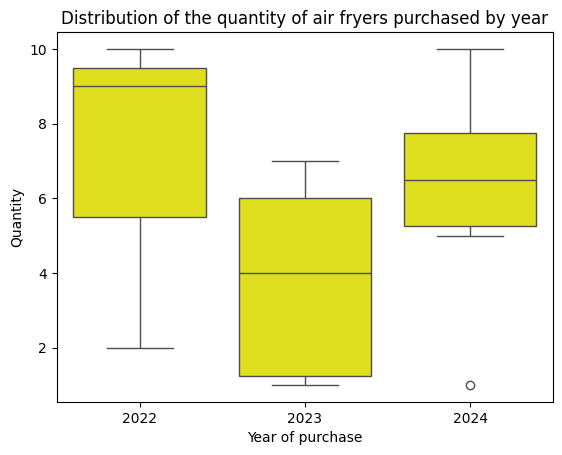

In [271]:
seaborn.boxplot(data=retail_store_sales[retail_store_sales["item_name"]=="Air Fryer"],x="year_of_transaction",y="quantity",color="yellow")
plt.xlabel("Year of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of air fryers purchased by year")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_air_fryers_purchased_by_year.png");

#### 💡**Insights:**
- The quantity of air fryers purchased was highest in the year 2022, which is between 2 and 10.
- Most of the 50% of the air fryers purchased in the year 2022 have a quantity of 9.
- The purchase of air fryers has reduced in the year 2023 compared to the previous year, 2022.
- The purchase of air fryers has again increased in the year 2024 with the total quantity between 5 and 10.
- Very few customers have purchased 1 air fryer in the year 2024.
- There are no purchases of air fryers in the year 2025.

###**Comparison of payment methods used for Online and In-store purchases**

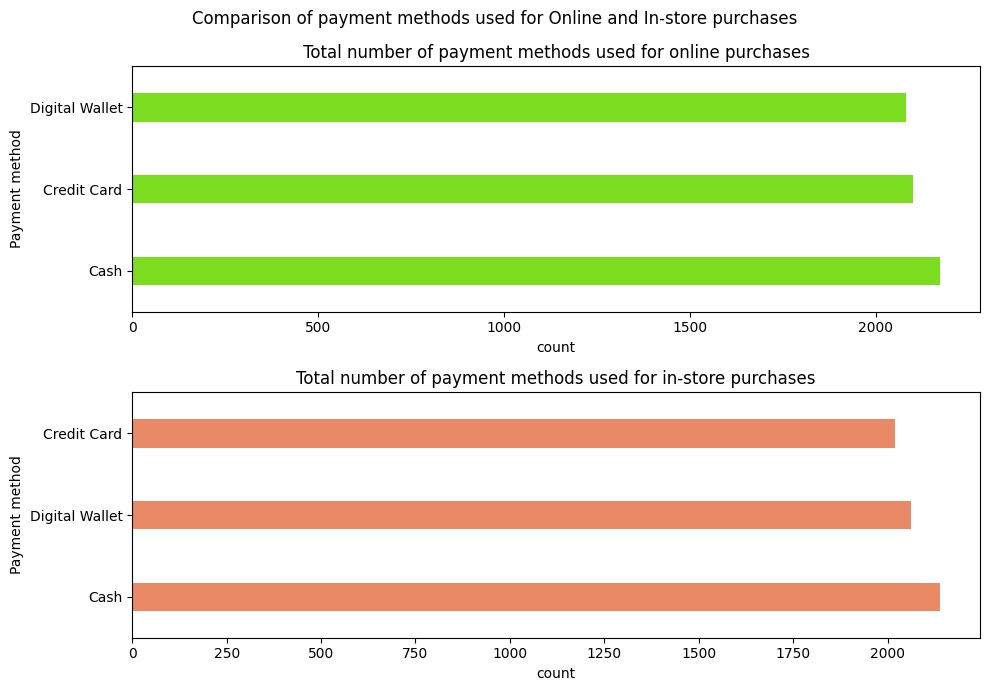

In [272]:
f, ax = plt.subplots(2,1,figsize=(10,7))
seaborn.countplot(y=retail_store_sales[(retail_store_sales["location"]=="Online")]["payment_method"],color="lawngreen",ax=ax[0],width=0.35)
ax[0].set_ylabel("Payment method")
ax[0].set_title("Total number of payment methods used for online purchases")
seaborn.countplot(y=retail_store_sales[(retail_store_sales["location"]=="In-store")]["payment_method"],color="coral",ax=ax[1],width=0.35)
ax[1].set_ylabel("Payment method")
ax[1].set_title("Total number of payment methods used for in-store purchases")
plt.suptitle("Comparison of payment methods used for Online and In-store purchases")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_payment_methods_used_for_online_and_instore_purchases.png");

#### 💡**Insights:**
- Cash payment is the most sought-after mode of payment for both online and in-store purchases in the retail store.
- Most of the customers who made online purchases have made payment through credit card as their second choice other than digital wallet.
- Digital wallet is the second most used payment method for in-store purchases.

###**Average of total amount spent by customers in online purchase by payment methods**

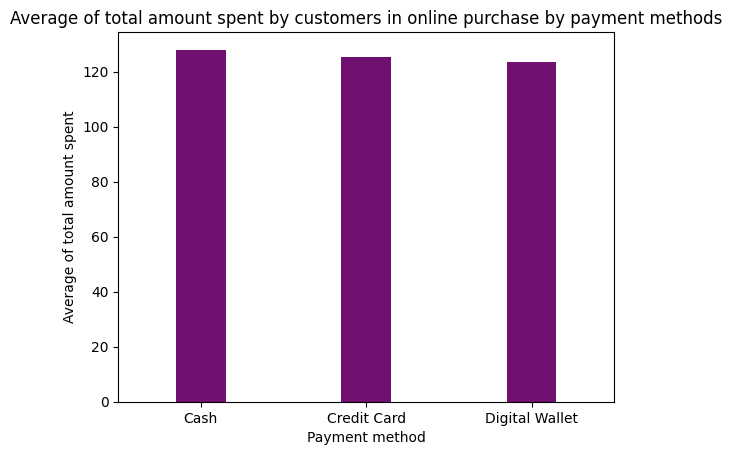

In [273]:
seaborn.barplot(x=retail_store_sales[retail_store_sales["location"]=="Online"].groupby("payment_method")["total_spent"].mean().index,y=retail_store_sales[retail_store_sales["location"]=="Online"].groupby("payment_method")["total_spent"].mean().values,width=0.3,color="purple")
plt.xlabel("Payment method")
plt.ylabel("Average of total amount spent")
plt.title("Average of total amount spent by customers in online purchase by payment methods")
plt.savefig("/kaggle/working/plots/average_of_total_amount_spent_by_customers_in_online_purchase_by_payment_methods.png");

#### 💡**Insights:**
- The average of the total amount spent by cash in online purchases is around 124.
- The average of the total amount spent by digital wallet in online purchases is around 120.

###**Top 7 most purchased items in milk products by total quantity**

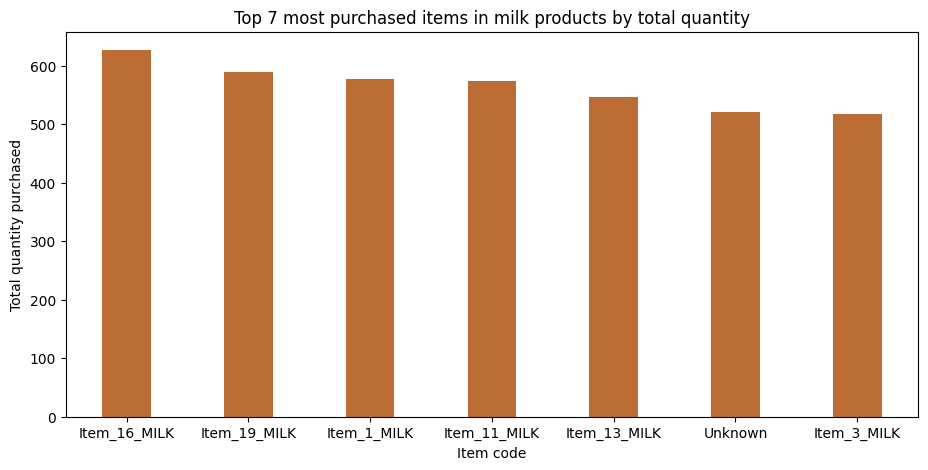

In [274]:
plt.figure(figsize=(11,5))
seaborn.barplot(x=retail_store_sales[retail_store_sales["category"]=="Milk Products"].groupby("item_code")["quantity"].sum().sort_values(ascending=False).head(7).index,y=retail_store_sales[retail_store_sales["category"]=="Milk Products"].groupby("item_code")["quantity"].sum().sort_values(ascending=False).head(7).values,width=.4,color="chocolate")
plt.xlabel("Item code")
plt.ylabel("Total quantity purchased")
plt.title("Top 7 most purchased items in milk products by total quantity")
plt.savefig("/kaggle/working/plots/top_7_most_purchased_items_in_milk_products_by_total_quantity.png");

#### 💡**Insights:**
- The item with the item code Item_16_MILK ranks first among the top 7 milk products based on the total amount spent by customers.
- The total quantity purchased by customers among the top 7 items in the milk products category did not exceed 620.

### **Distribution of the total amount spent for patisseries by payment method**

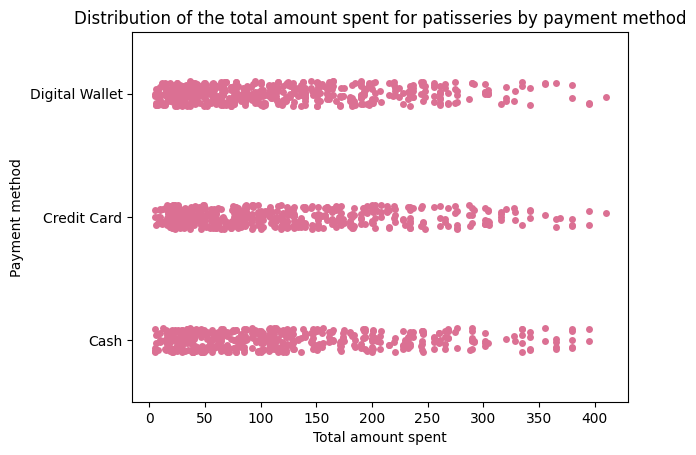

In [275]:
seaborn.stripplot(x=retail_store_sales[(retail_store_sales["category"]=="Patisserie")]["total_spent"],y=retail_store_sales[(retail_store_sales["category"]=="Patisserie")]["payment_method"],color='palevioletred')
plt.xlabel("Total amount spent")
plt.ylabel("Payment method")
plt.title("Distribution of the total amount spent for patisseries by payment method")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_for_patisseries_by_payment_method.png");

#### 💡**Insights:**
- Few of the payments for patisseries that are made through digital wallet and credit card exceed the total amount spent of 400.
- The payments made through digital wallet are less for the total amount between 270 and 400 compared to the payments made by credit card and cash for patisseries.

###**Total amount spent on furnitures by year of purchase**

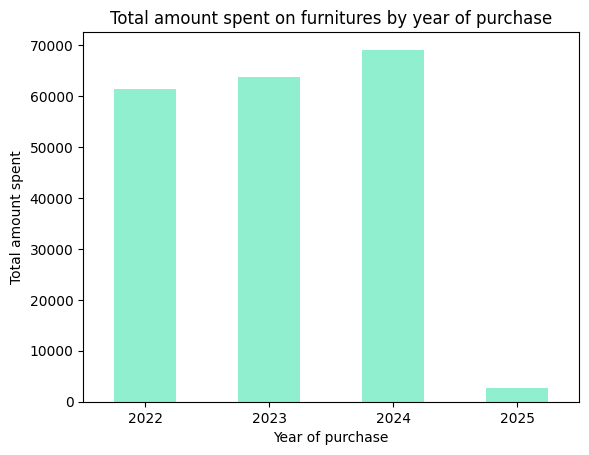

In [276]:
seaborn.barplot(x=retail_store_sales[(retail_store_sales["category"]=="Furniture")].groupby("year_of_transaction")["total_spent"].sum().index,y=retail_store_sales[(retail_store_sales["category"]=="Furniture")].groupby("year_of_transaction")["total_spent"].sum().values,width=0.5,color="aquamarine")
plt.xlabel("Year of purchase")
plt.ylabel("Total amount spent")
plt.title("Total amount spent on furnitures by year of purchase")
plt.savefig("/kaggle/working/plots/total_amount_spent_on_furnitures_by_year_of_purchase.png");

#### 💡**Insights:**
- The total amount spent on furniture in 2024 is higher than the year 2023.
- 2025 has the lowest total amount spent on furniture, which is around 2500.

###**Comparison of the distribution of total amount spend by year and payment method**

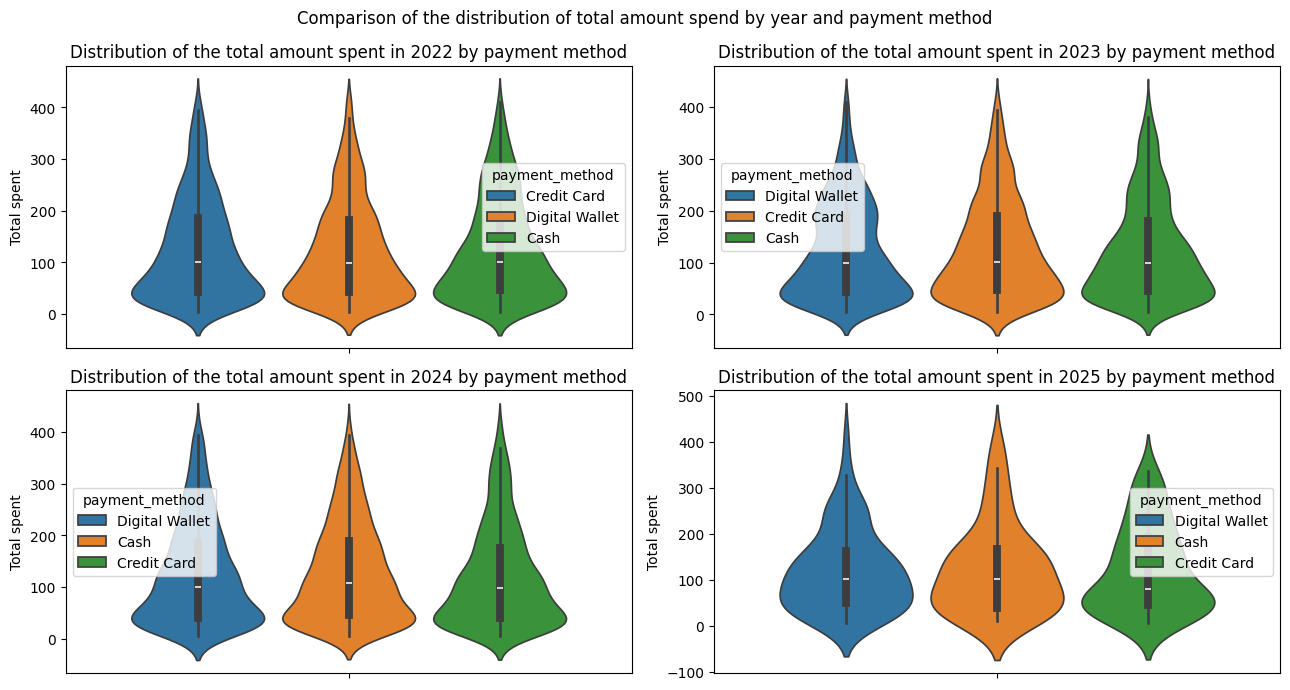

In [277]:
f,ax = plt.subplots(2,2,figsize=(13,7))
year_starting = 2022
for rowIndex in range(2):
  for colIndex in range(2):
    seaborn.violinplot(data=retail_store_sales[retail_store_sales["year_of_transaction"]==year_starting],y="total_spent",hue="payment_method",ax=ax[rowIndex,colIndex],gap=0.12)
    ax[rowIndex,colIndex].set_ylabel("Total spent")
    ax[rowIndex,colIndex].set_title(f"Distribution of the total amount spent in {year_starting} by payment method")
    year_starting += 1
plt.suptitle("Comparison of the distribution of total amount spend by year and payment method")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_the_distribution_of_the_total_amount_spent_by_year_and_payment_method.png");

#### 💡**Insights:**
- Most of the total amount spent in 2025 through digital wallet and cash is for the amount between 5 and 200.
- Most of the total amount spent in 2025 through credit card is between 5 and 150.
- Most of the total amount spent in the years 2022 and 2024 through cash is between 5 and 100.
- The usage of digital wallets as a payment method is high in the year 2023 for the total amount that ranges between 5 and 100, and from 190 to 230.

###**Top 5 most purchased categories in January at retail store by total quantity**

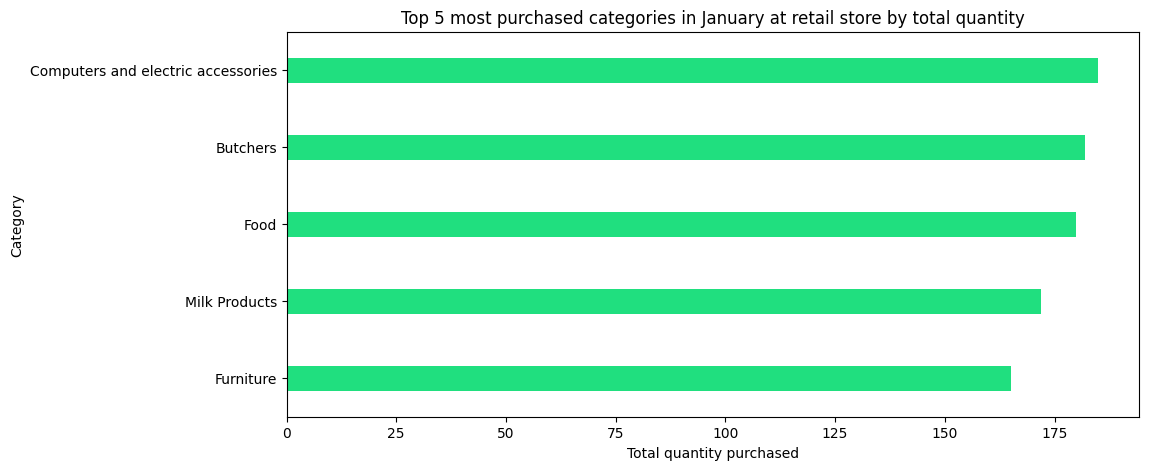

In [278]:
plt.figure(figsize=(11,5))
items_bought_in_january = retail_store_sales[retail_store_sales["month_of_transaction"]=="January"].groupby("category")["quantity"].count().sort_values(ascending=False).head()
seaborn.barplot(y=items_bought_in_january.index,x=items_bought_in_january.values,width=0.33,color="springgreen")
plt.xlabel("Total quantity purchased")
plt.ylabel("Category")
plt.title("Top 5 most purchased categories in January at retail store by total quantity")
plt.savefig("/kaggle/working/plots/top_5_most_purchased_categories_in_january_at_retail_store_by_total_quantity.png");

#### 💡**Insights:**
- The sales of computers and electric accessories are high in the month of January.
- Edible categories like butchers, food, and milk products are also among the top 5 categories most sold in January.

###**Comparison of the top 5 most purchased categories by month and total quantity**

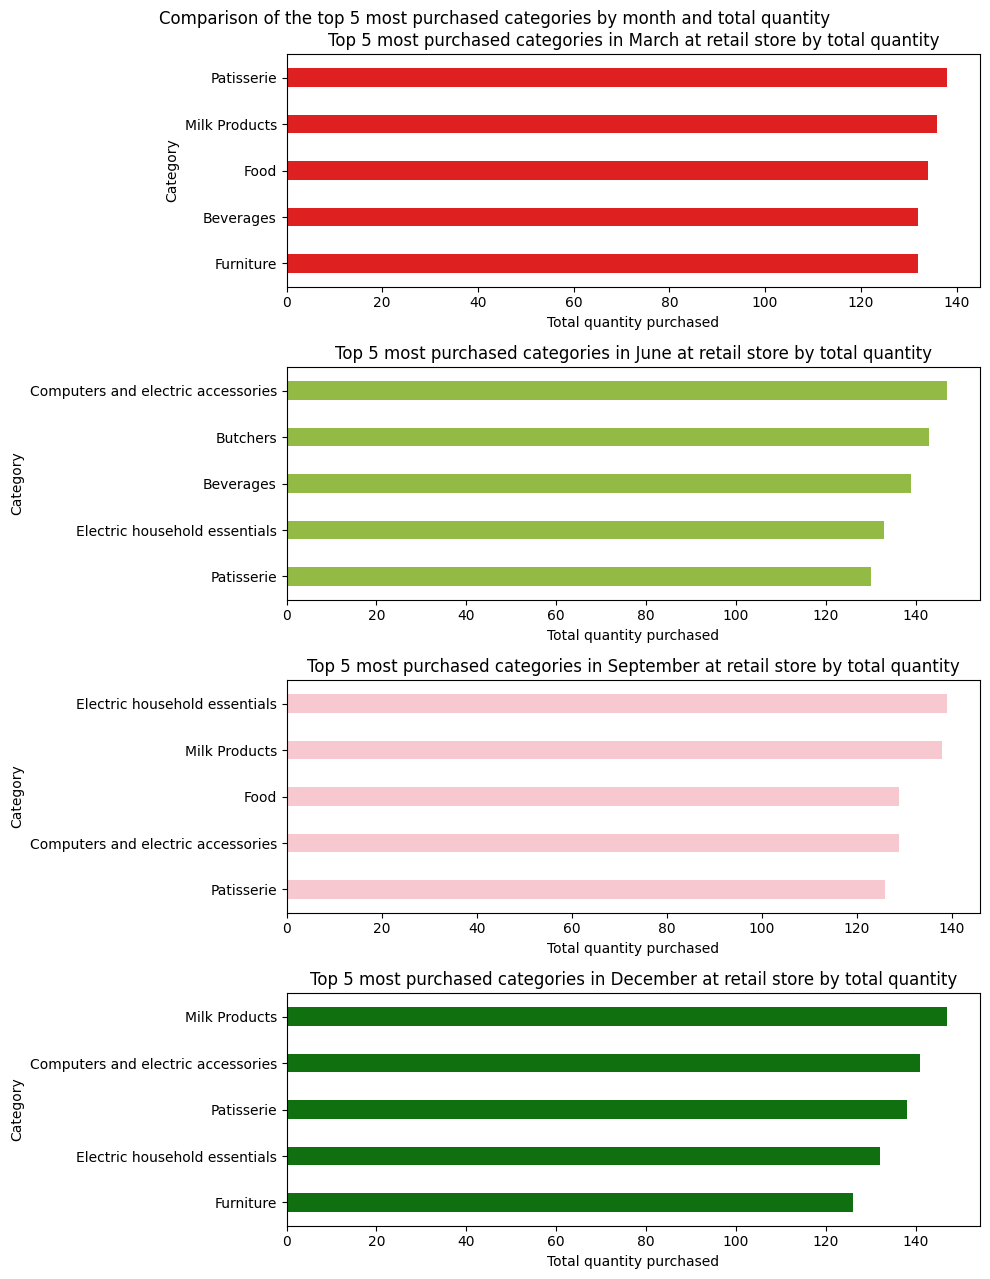

In [279]:
f, ax = plt.subplots(4,1,figsize=(10,13))
items_bought_in_march = retail_store_sales[retail_store_sales["month_of_transaction"]=="March"].groupby("category")["quantity"].count().sort_values(ascending=False).head()
items_bought_in_june = retail_store_sales[retail_store_sales["month_of_transaction"]=="June"].groupby("category")["quantity"].count().sort_values(ascending=False).head()
items_bought_in_sept = retail_store_sales[retail_store_sales["month_of_transaction"]=="September"].groupby("category")["quantity"].count().sort_values(ascending=False).head()
items_bought_in_december = retail_store_sales[retail_store_sales["month_of_transaction"]=="December"].groupby("category")["quantity"].count().sort_values(ascending=False).head()
seaborn.barplot(y=items_bought_in_march.index,x=items_bought_in_march.values,width=0.4,color="red",ax=ax[0])
seaborn.barplot(y=items_bought_in_june.index,x=items_bought_in_june.values,width=0.4,color="yellowgreen",ax=ax[1])
seaborn.barplot(y=items_bought_in_sept.index,x=items_bought_in_sept.values,width=0.4,color="pink",ax=ax[2])
seaborn.barplot(y=items_bought_in_december.index,x=items_bought_in_december.values,width=0.4,color="green",ax=ax[3])
months_arr = ["March","June","September","December"]
for rowIndex in range(4):
  ax[rowIndex].set_xlabel("Total quantity purchased")
  ax[rowIndex].set_ylabel("Category")
  ax[rowIndex].set_title(f"Top 5 most purchased categories in {months_arr[rowIndex]} at retail store by total quantity");
  rowIndex += 1
plt.suptitle("Comparison of the top 5 most purchased categories by month and total quantity")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_the_top_5_most_purchased_categories_by_month_and_total_quantity.png");

#### 💡**Insights:**
- Patisserie stays in the top 5 most purchased categories in March, June, September, and December.
- The purchases of patisseries were high in March and dropped to less than 130 items in June and September.
- The purchase of beverages increased from around 132 to 140 in the months of March to June.
- Food items are among the top 5 most purchased categories only in the months of March and September.

###**Trend of total amount spent by customers in 2022**

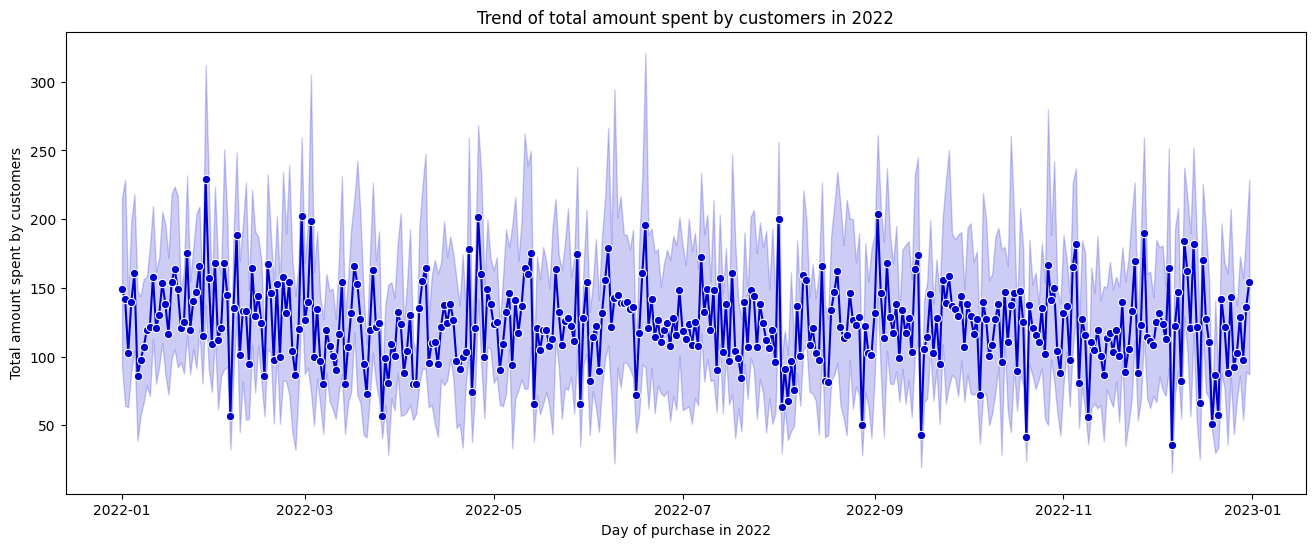

In [280]:
plt.figure(figsize=(16,6))
seaborn.lineplot(data=retail_store_sales[retail_store_sales["year_of_transaction"]==2022],x="transaction_date",y="total_spent",marker="o",color="mediumblue")
plt.xlabel("Day of purchase in 2022")
plt.ylabel("Total amount spent by customers")
plt.title("Trend of total amount spent by customers in 2022")
plt.savefig("/kaggle/working/plots/trend_of_total_amount_spent_by_customers_in_2022.png");

#### 💡**Insights:**
- The purchases are high in the month of February in the year 2022, which has a total amount of around 230.
- The purchases have more sudden drops after the month of September in the year 2022 compared to the months before September in the year 2022.
- The total amount spent by customers has dropped to less than 50 in the month of December in 2022.
- There was stable growth in the total amount spent by customers between the mid of June and August in 2022.

###**Top 10 cheapest prices in the retail store**

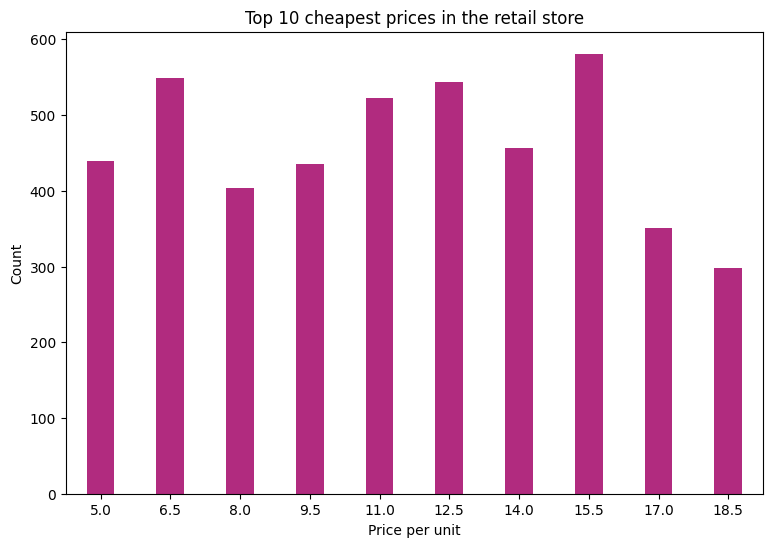

In [281]:
plt.figure(figsize=(9,6))
seaborn.barplot(x=retail_store_sales["price_per_unit"].value_counts().sort_index().head(10).index,y=retail_store_sales["price_per_unit"].value_counts().sort_index().head(10).values,color="mediumvioletred",width=0.40)
plt.xlabel("Price per unit")
plt.ylabel("Count")
plt.title("Top 10 cheapest prices in the retail store")
plt.savefig("/kaggle/working/plots/top_10_cheapest_prices_in_the_retail_store.png");

#### 💡**Insights:**
- The item having the lowest price in the retail store of 5 is around 430.
- Most of the items having the lowest price next to 5 in the retail store is 6.5.
- Among the top 10 cheapest items sold, the items having a price of 15.5 are maximum.

###**Top 5 categories purchased in online mode by count of purchases**

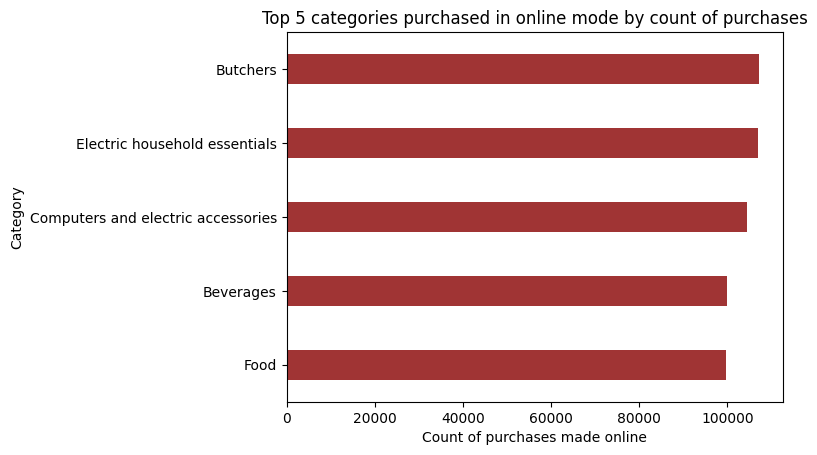

In [282]:
top_categories_online = retail_store_sales[retail_store_sales["location"]=="Online"].groupby("category")["total_spent"].sum().sort_values(ascending=False).head(5)
seaborn.barplot(y=top_categories_online.index,x=top_categories_online.values,width=0.4,color="firebrick")
plt.xlabel("Count of purchases made online")
plt.ylabel("Category")
plt.title("Top 5 categories purchased in online mode by count of purchases")
plt.savefig("/kaggle/working/plots/top_5_categories_purchased_in_online_mode_by_count_of_purchases.png");

#### 💡**Insights:**
- Customers have mostly purchased items in the butchers category through online mode.
- The number of items sold in the butchers and electric household essentials is around 110000.
- The items in the edible categories like butchers, beverages, and food are among the top 5 most purchased categories through online mode.

###**Distribution of the quantity of items purchased in the butchers category by day of purchase**

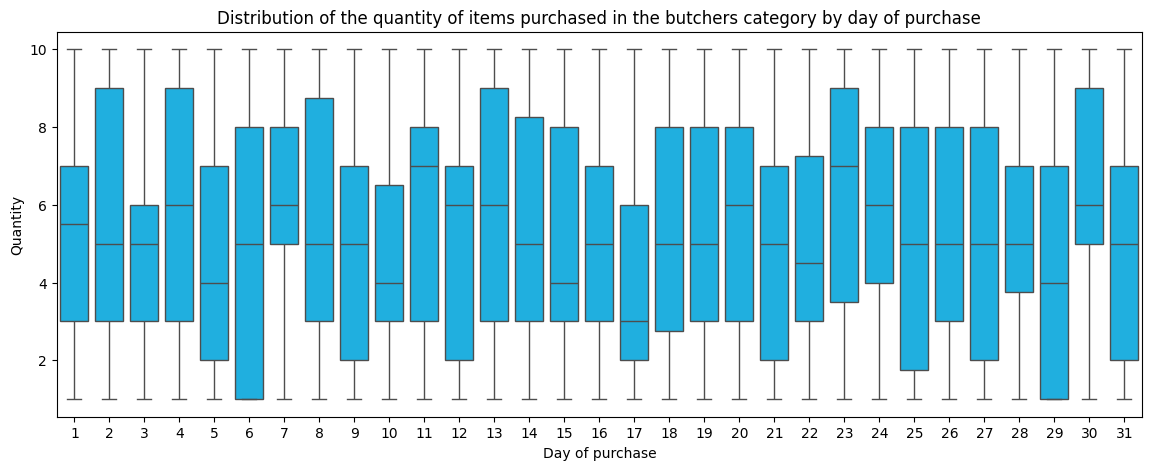

In [283]:
plt.figure(figsize=(14,5))
seaborn.boxplot(data=retail_store_sales[retail_store_sales["category"]=="Butchers"],x="day_of_transaction",y="quantity",color="deepskyblue")
plt.xlabel("Day of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of items purchased in the butchers category by day of purchase")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_items_purchased_in_the_butchers_category_by_day_of_purchase.png");

#### 💡**Insights:**
- The total number of items purchased in the butchers category is high on the 2nd, 4th, 13th, 23rd, and 30th in all months between 2022 and 2025.
- The number of items sold in the butchers category is low as 1 on the 6th and 29th in all months between 2022 and 2025.

###**Distribution of the total amount spent by customers on food category by day of the week purchased**

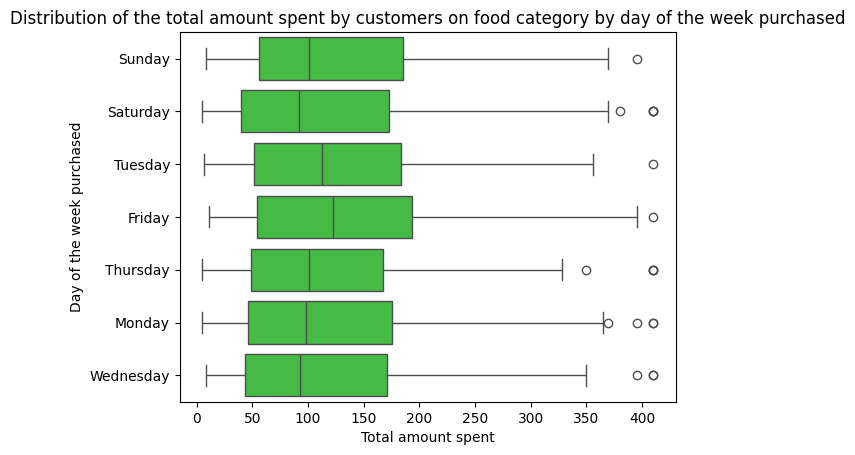

In [284]:
seaborn.boxplot(data=retail_store_sales[retail_store_sales["category"]=="Food"],x="total_spent",y="day_name_of_purchase",color="limegreen")
plt.xlabel("Total amount spent")
plt.ylabel("Day of the week purchased")
plt.title("Distribution of the total amount spent by customers on food category by day of the week purchased")
plt.savefig("/kaggle/working/plots/distribution_of_the_total_amount_spent_by_customers_on_food_category_by_day_of_the_week_purchased.png");

#### 💡**Insights:**
- The customers have spend the most of the total amount on Friday which is between 50 to 190 than the other days of the week.
- The total amount spent on Friday ranges between 5 and 390.
- Thursday has mostly the lowest total amount spent which is between 5 and 320.
- Few customers have spent more than 400 for some purchases on every day of the week.

###**Average of the total amount spent by day name**

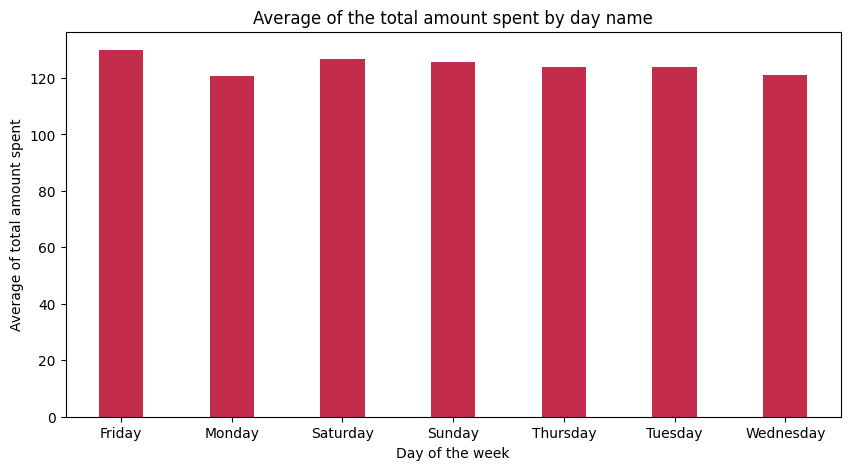

In [285]:
plt.figure(figsize=(10,5))
seaborn.barplot(x=retail_store_sales.groupby("day_name_of_purchase")["total_spent"].mean().index,y=retail_store_sales.groupby("day_name_of_purchase")["total_spent"].mean().values,width=0.40,color="crimson")
plt.xlabel("Day of the week")
plt.ylabel("Average of total amount spent")
plt.title("Average of the total amount spent by day name")
plt.savefig("/kaggle/working/plots/average_of_the_total_amount_spent_by_day_name.png");

#### 💡**Insights:**
- Friday has the highest average of total amount spent by customers in the retail store.
- Saturday has the second highest average of total amount spent by customers.
- Monday has the lowest average of total amount spent, which is around 120.

## 🏪**Multivariate Analysis**

### **Pairwise relationship between variables**

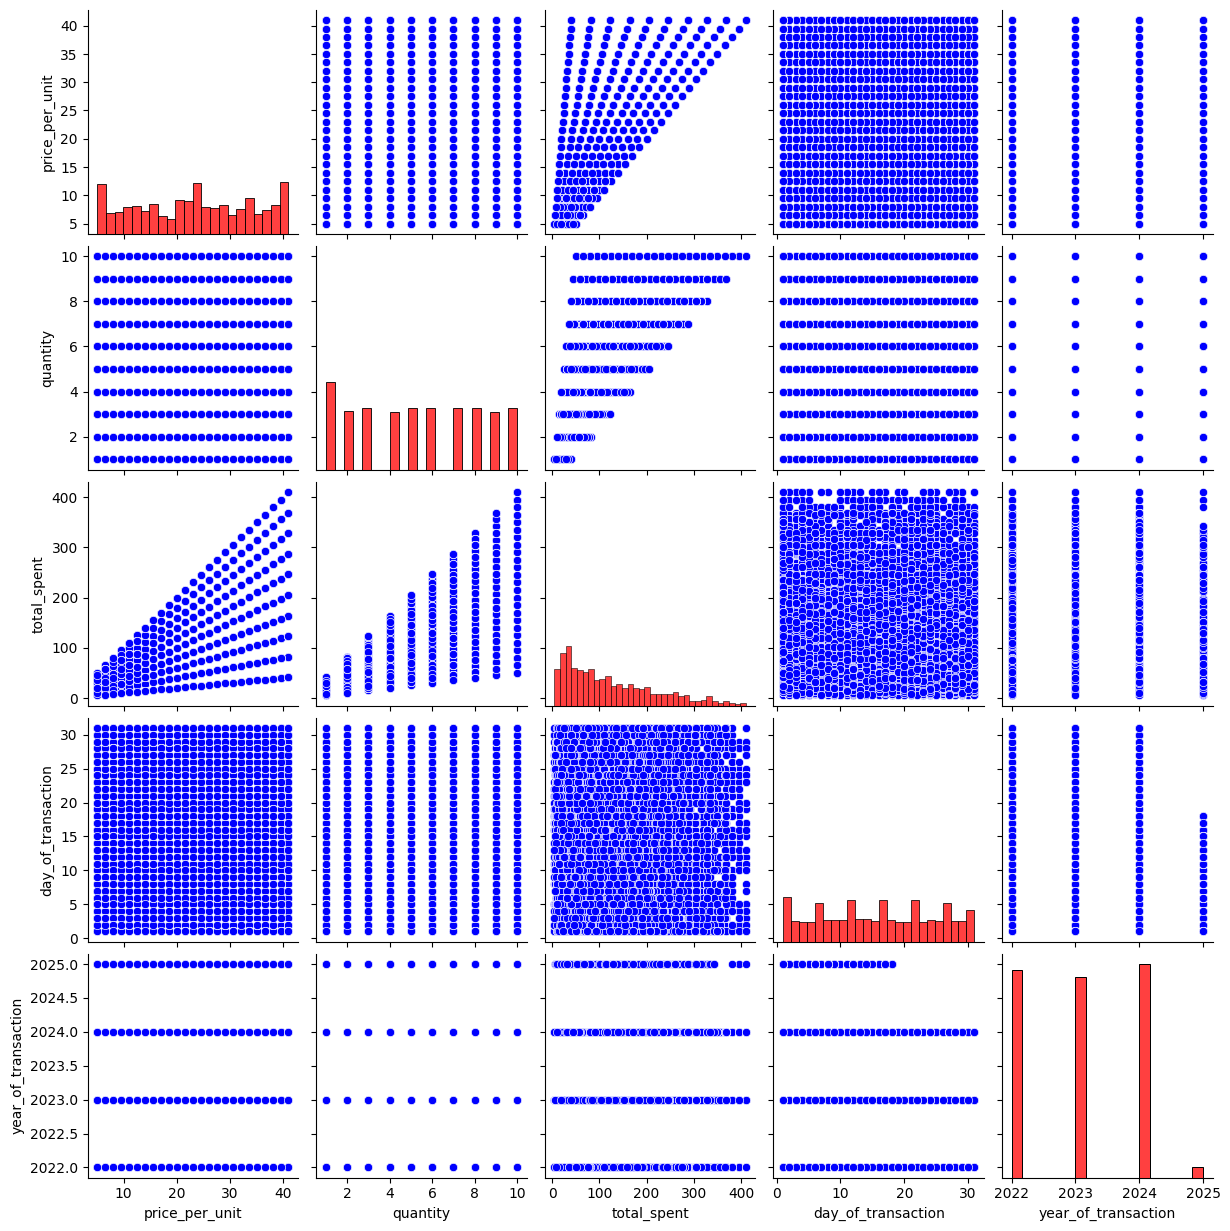

In [286]:
seaborn.pairplot(retail_store_sales,diag_kws=dict(color="red"),plot_kws=dict(color="blue"))
plt.savefig("/kaggle/working/plots/pairwise_relationship_between_variables.png");

#### 💡**Insights:**
- The total amount spent is low when the price per unit is low and high when the price per unit gets increased, indicating a strong positive relationship between price per unit and total amount spent by customers.
- There is a strong positive relationship between quantity and total amount spent, indicating that purchasing larger quantities of items directly increases the total amount spent.
- There is a weak relationship between year of transaction and other factors, as the relationship remains stable across the years.
- The day of transaction does not have a clear relationship with the total amount spent by customers or the quantity, indicating a weak relationship.
- The total amount spent is a right-skewed distribution, indicating that most of the purchases are for small spending amounts, while fewer purchases are for high spending.

###**Correlation Heatmap of transaction variables**

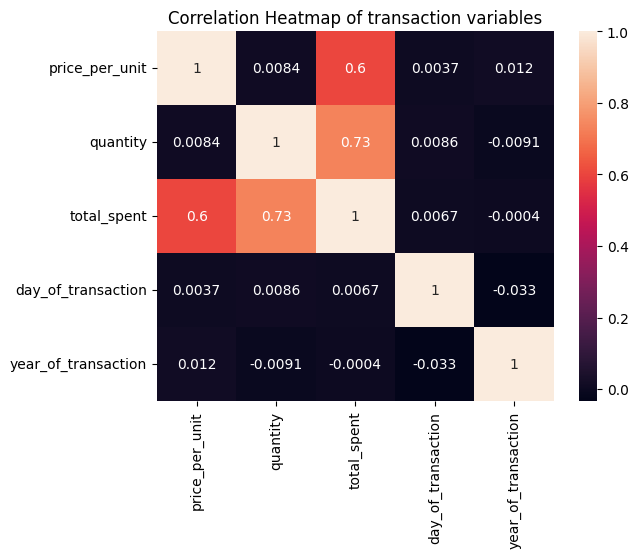

In [287]:
correlation_matrix = retail_store_sales.corr(numeric_only=True)
seaborn.heatmap(correlation_matrix,annot=True)
plt.title("Correlation Heatmap of transaction variables")
plt.savefig("/kaggle/working/plots/correlation_heatmap_of_transaction_variables.png");

#### 💡**Insights:**
- A strong positive correlation exists between the quantity of items purchased and the total amount spent on the purchase, indicating that higher quantities contribute to higher spending by customers.
- A moderative positive correlation exists between the price per unit and the total amount spent by customers, indicating that increasing the total amount spent depends on the increasing price per unit.
- The quantity and price per unit have a weak correlation indicating that price per unit does not affect most of the quantity of items purchased by customers.
- No correlation between day of transaction and other variables like total amount spent, quantity, price per unit, and year of transaction.
- The year of transaction does not affect the total amount spent and quantity, as it has a negative weak correlation.

###**Total amount spent by customers in the year 2022 by location of purchase**

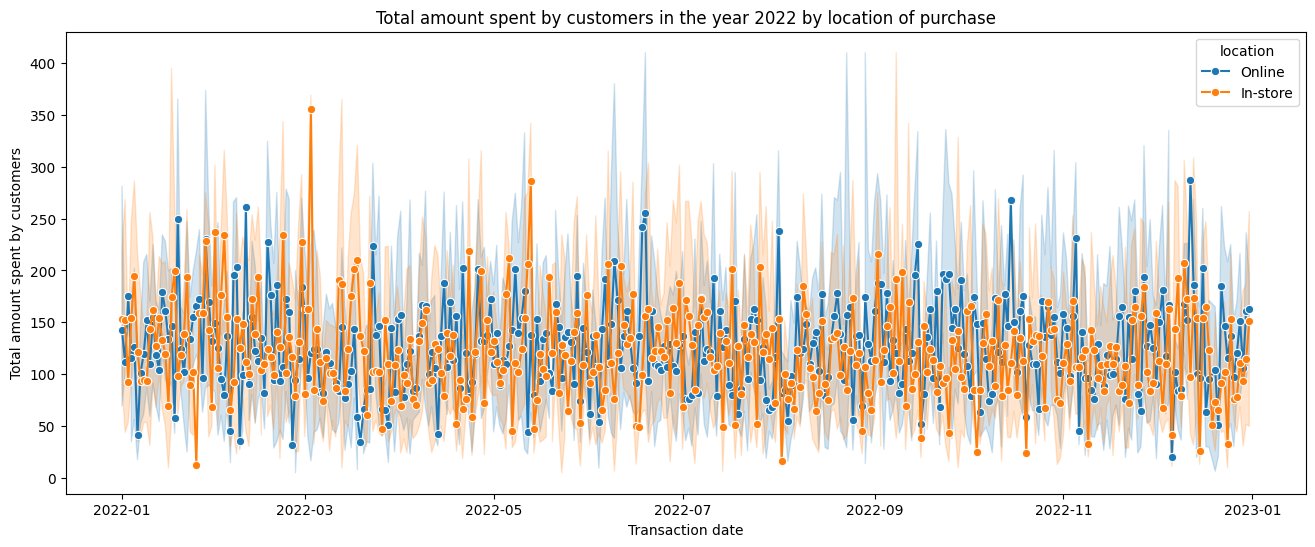

In [288]:
plt.figure(figsize=(16,6))
seaborn.lineplot(data=retail_store_sales[retail_store_sales["year_of_transaction"]==2022],x="transaction_date",y="total_spent",hue="location",marker="o")
plt.xlabel("Transaction date")
plt.ylabel("Total amount spent by customers")
plt.title("Total amount spent by customers in the year 2022 by location of purchase")
plt.savefig("/kaggle/working/plots/total_amount_spent_by_customers_in_the_year_2022_by_location_of_purchase.png");

#### 💡**Insights:**
- The maximum total amount spent by customers in the year 2022 is in the month of March through online purchases, which is more than 350.
- The second highest total amount spent by customers in the year 2022 is in the mid of May through online purchase.
- The maximum total amount spent through in-store purchases happened in December 2022.
- Most of the purchases made online and in-store have a total amount between 50 and 200.

### **Total amount spent by customers over time based on date of purchase**

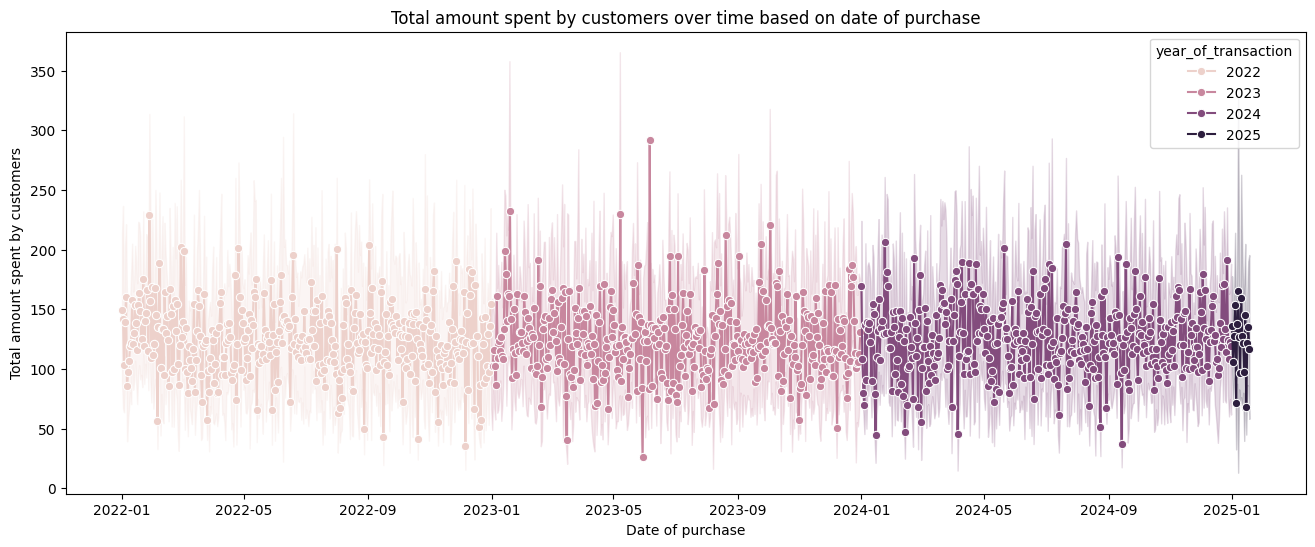

In [289]:
plt.figure(figsize=(16,6))
seaborn.lineplot(data=retail_store_sales,x="transaction_date",y="total_spent",hue="year_of_transaction",marker="o")
plt.xlabel("Date of purchase")
plt.ylabel("Total amount spent by customers")
plt.title("Total amount spent by customers over time based on date of purchase")
plt.savefig("/kaggle/working/plots/total_amount_spent_by_customers_over_time_based_on_date_of_purchase.png");

#### 💡**Insights:**
- The maximum total amount spent in all years is in June of 2023, which is between 275 and 300.
- The year 2022 has a small amount of total spending compared to the year 2023.
- The maximum total amount spent in the year 2024 is between 170 and 200.
- The lowest total amount spent is in the year 2023.

### **Relationship between the total amount spent and the price per unit on items in the food category**

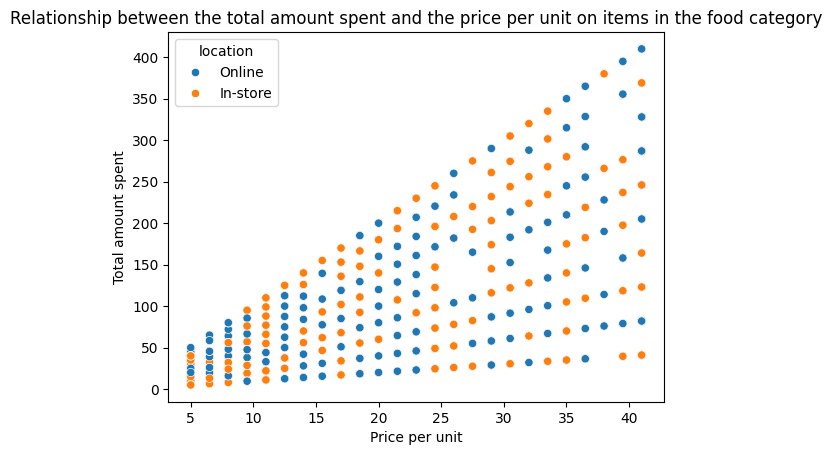

In [290]:
seaborn.scatterplot(data=retail_store_sales[retail_store_sales["category"]=="Food"],x="price_per_unit",y="total_spent",hue="location")
plt.xlabel("Price per unit")
plt.ylabel("Total amount spent")
plt.title("Relationship between the total amount spent and the price per unit on items in the food category")
plt.savefig("/kaggle/working/plots/relationship_between_the_total_amount_spent_and_the_price_per_unit_on_items_in_the_food_category.png");

#### 💡**Insights:**
- The relationship between the price per unit and the total amount spent is positively increasing both for online and in-store purchases.

### **Distribution of the quantity of air fryers purchased over the years by payment method**

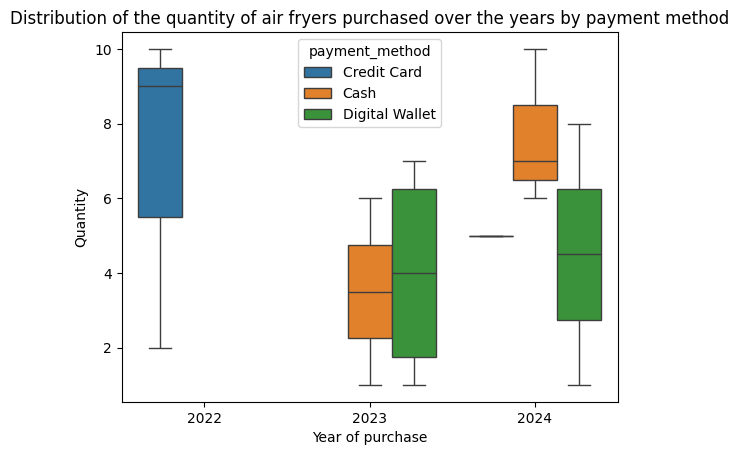

In [291]:
seaborn.boxplot(data=retail_store_sales[retail_store_sales["item_name"]=="Air Fryer"],x="year_of_transaction",y="quantity",hue="payment_method")
plt.xlabel("Year of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of air fryers purchased over the years by payment method")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_air_fryers_purchased_over_the_years_by_payment_method.png");

#### 💡**Insights:**
- Credit card is the only payment method used for purchasing air fryers in the year 2022.
- From the year 2023, only cash and digital wallets are used as payment methods for purchasing air fryers, leaving the credit card.
- The distribution of the quantity of air fryers bought in the year 2022 through credit card ranges widely between 2 and 10, whereas the distribution of the quantity of air fryers bought in 2024 through cash is high between 7 and 9.

### Distribution of the quantity of coffee makers purchased over the years by payment method

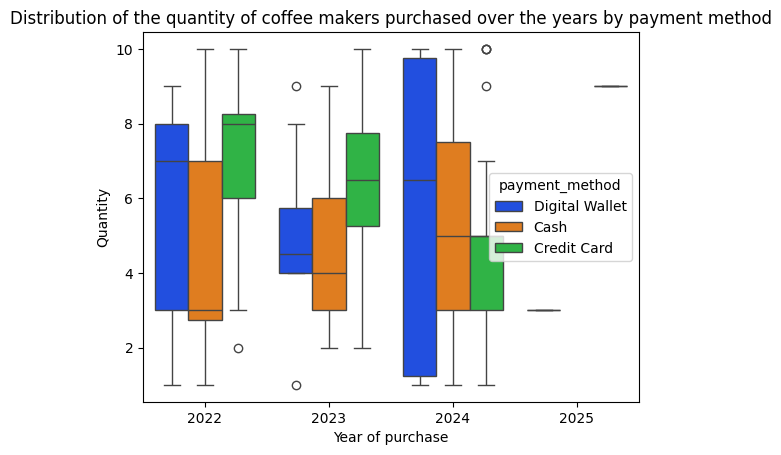

In [292]:
seaborn.boxplot(data=retail_store_sales[retail_store_sales["item_name"]=="Coffee Maker"],x="year_of_transaction",y="quantity",hue="payment_method",palette="bright")
plt.xlabel("Year of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of coffee makers purchased over the years by payment method")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_coffee_makers_purchased_over_the_years_by_payment_method.png");

#### 💡**Insights:**
- The distribution of the quantity of coffee makers purchased through digital wallets in the year 2024 is vaster than in the year 2023.
- 1 to 10 coffee makers are purchased using digital wallets in the year 2024, and about, 4 to 5 in the year 2023.
- A few of the quantities of coffee makers purchased through credit card are 2 in the year 2022, as most of the coffee makers purchased through credit card in 2022 are between 6 and 8.
- Most of the quantities of coffee makers purchased through credit card in the year 2024 are between 3 and 5, while a few of the purchases made through credit cards are between 9 and 10.

###**Distribution of the quantity of bean bags purchased by year of purchase and location**

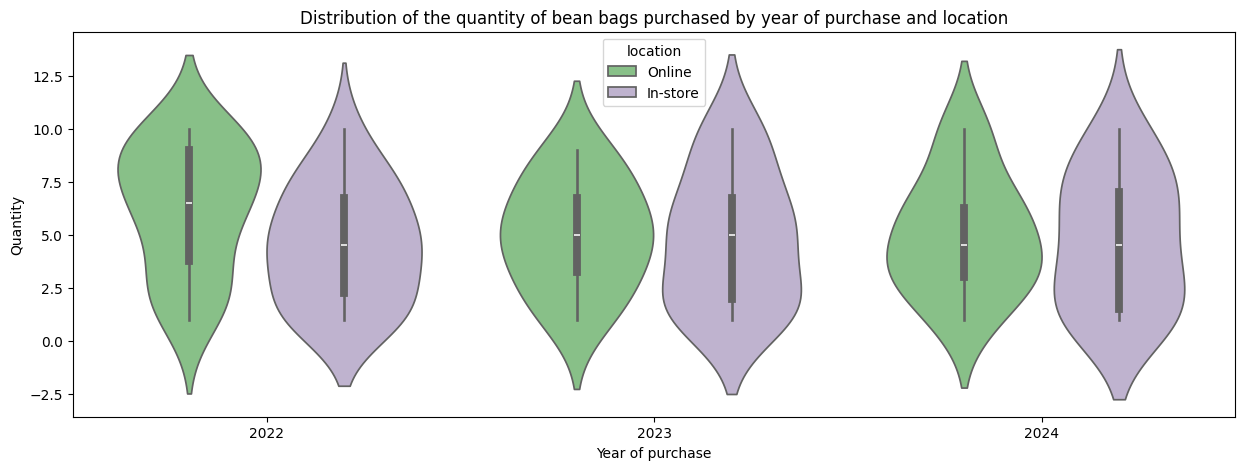

In [293]:
plt.figure(figsize=(15,5))
seaborn.violinplot(data=retail_store_sales[(retail_store_sales["item_name"]=="Bean Bag")],x="year_of_transaction",y="quantity",hue="location",palette="Accent")
plt.xlabel("Year of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of bean bags purchased by year of purchase and location")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_beanbags_purchased_by_year_of_purchase_and_location.png");

#### 💡**Insights:**
- The purchase of the beanbags in in-store shopping over the years is similar, indicating consistent shopping and purchasing behaviour.
- In 2022, the distribution of the quantity of beanbags purchased online is higher between 5 and 10 than in 2023 and 2024.


###**Usage of cash as payment method based on day of purchase, total amount spent and year of purchase**

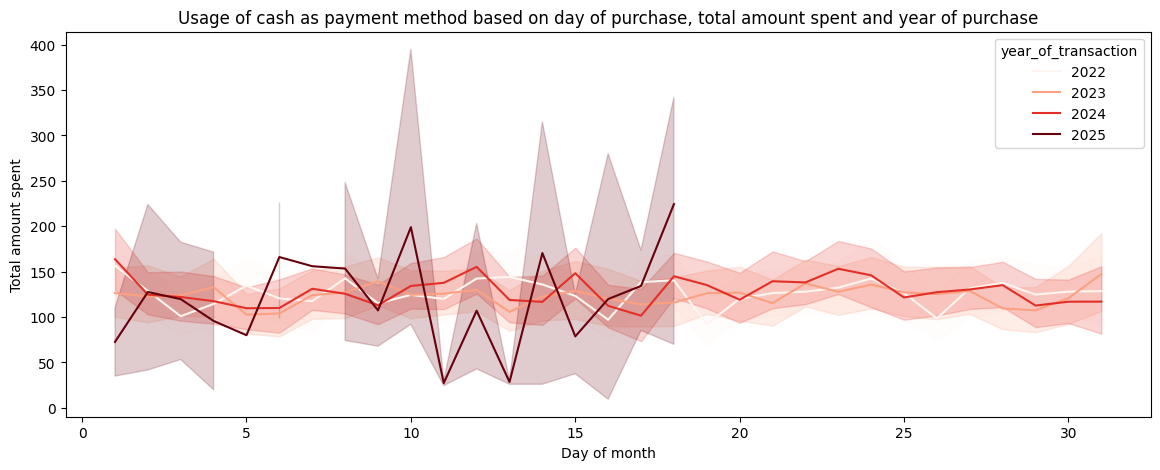

In [294]:
plt.figure(figsize=(14,5))
seaborn.lineplot(data=retail_store_sales[retail_store_sales["payment_method"]=="Cash"],x="day_of_transaction",y="total_spent",hue="year_of_transaction",palette="Reds")
plt.xlabel("Day of month")
plt.ylabel("Total amount spent")
plt.title("Usage of cash as payment method based on day of purchase, total amount spent and year of purchase")
plt.savefig("/kaggle/working/plots/usage_of_cash_as_payment_method_based_on_day_of_purchase_total_amount_spent_and_year_of_purchase.png");

#### 💡**Insights:**
- The usage of cash for payment on days of the month remained consistent between 2022 and 2024.
- Cash is used for a higher total amount of above 200 in the year 2025 around 17th.

###**Usage of credit card as payment method based on day of purchase, total amount spent and year of purchase**

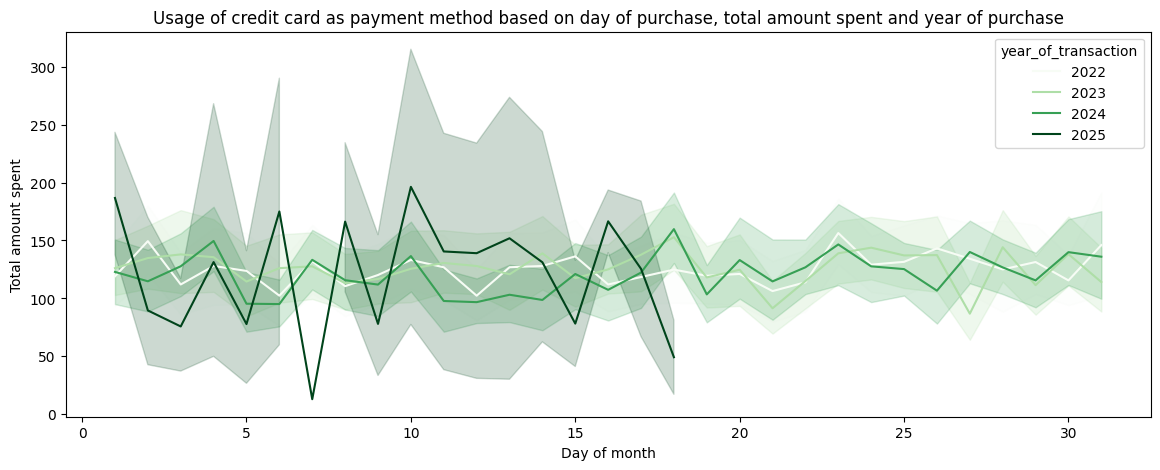

In [295]:
plt.figure(figsize=(14,5))
seaborn.lineplot(data=retail_store_sales[retail_store_sales["payment_method"]=="Credit Card"],x="day_of_transaction",y="total_spent",hue="year_of_transaction",palette="Greens")
plt.xlabel("Day of month")
plt.ylabel("Total amount spent")
plt.title("Usage of credit card as payment method based on day of purchase, total amount spent and year of purchase")
plt.savefig("/kaggle/working/plots/usage_of_credit_card_as_payment_method_based_on_day_of_purchase_total_amount_spent_and_year_of_purchase.png");

#### 💡**Insights:**
- The usage of credit cards has dropped for a total amount of around 10 on the 7th in 2025 and around 50 on the 18th in 2025.
- The credit card usage stays consistent on all the days of a month in the years 2022 to 2024 for a total amount between 75 and 150.

### **Distribution of the quantity of items purchased from butchers category by day name and location of purchase**

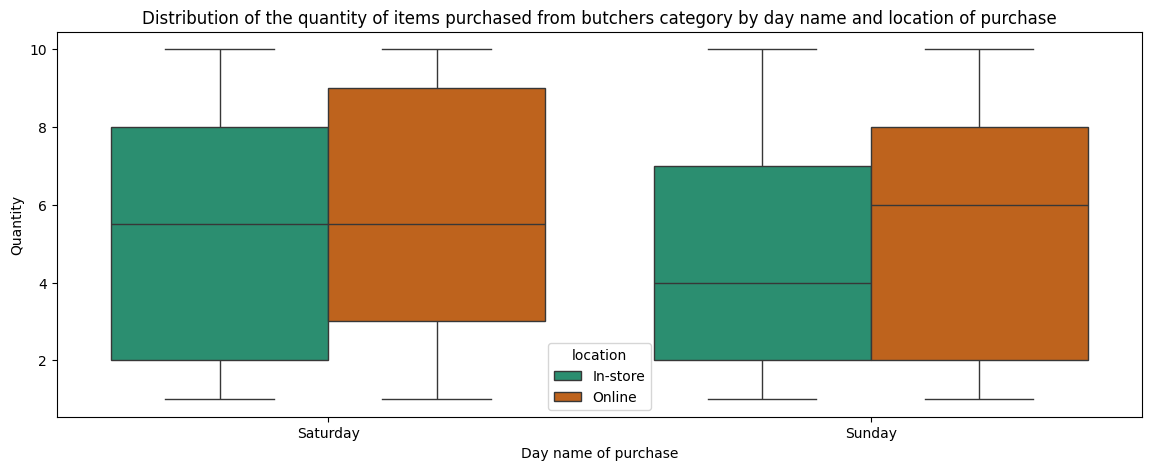

In [296]:
plt.figure(figsize=(14,5))
seaborn.boxplot(data=retail_store_sales[(retail_store_sales["category"]=="Butchers")&((retail_store_sales["day_name_of_purchase"]=="Saturday")|(retail_store_sales["day_name_of_purchase"]=="Sunday"))],x="day_name_of_purchase",y="quantity",hue="location",palette="Dark2")
plt.xlabel("Day name of purchase")
plt.ylabel("Quantity")
plt.title("Distribution of the quantity of items purchased from butchers category by day name and location of purchase")
plt.savefig("/kaggle/working/plots/distribution_of_the_quantity_of_items_purchased_from_butchers_category_by_day_name_and_location_of_purchase.png");

#### 💡**Insights:**
- Most of the products in the butchers category are purchased on Saturday rather than on Sunday.
- The quantity of products in the butchers category purchased through online shopping on Saturday is mostly between 3 to 9, whereas the quantity of products purchased through online shopping on Sunday is mostly between 2 to 8.
- Customers purchased higher quantities of products from the butchers category on Saturday than on Sunday.
- The products in the butchers category are purchased more by online shopping than in-store shopping on both Saturday and Sunday.

In [297]:
retail_store_sales.to_csv("cleaned_dataset_retail_stores.csv")